# Severidad de accidentes viales en EE. UU. con PySpark MLlib

**Autor:** Emiliano Camacho Ponce (A01712408) · ITESM

**Dataset:** [US Accidents (2016–2023)](https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents) — Sobhan Moosavi, Kaggle

**Herramientas:** Google Colab · Apache Spark (PySpark + MLlib) · Tableau

## Objetivo
Construir un modelo de clasificación que, con la información disponible en el momento en que se reporta un accidente
(ubicación, hora, clima y elementos de la vía), prediga si el accidente será de alta severidad (impacto alto en el tráfico).

## 0. Descripción del dataset

US Accidents (2016–2023) es un conjunto de datos público de accidentes de tránsito a nivel nacional en Estados Unidos,
publicado en Kaggle por Sobhan Moosavi. Los registros se recolectaron de forma continua,
de febrero de 2016 a marzo de 2023, a partir de varias APIs de tráfico que transmiten eventos reportados por
departamentos de transporte federales y estatales, cuerpos policiales, cámaras de tráfico y sensores en las vías.

| Característica | Valor |
|---|---|
| Archivo | `US_Accidents_March23.csv` |
| Tamaño | 3.06 GB |
| Registros | 7,728,394 (cada fila es un accidente) |
| Columnas | 46 |
| Cobertura | 49 estados de EE. UU., feb-2016 a mar-2023 |

**Grupos de variables**

| Grupo | Columnas | Contenido |
|---|---|---|
| Identificación | `ID`, `Source` | Identificador único y API/proveedor que reportó el evento |
| **Severidad (objetivo)** | `Severity` | Escala 1–4 del **impacto en el tráfico**: 1 = retraso corto, 4 = retraso largo. No mide lesiones |
| Tiempo | `Start_Time`, `End_Time`, `Timezone`, `Weather_Timestamp` | Inicio y fin del impacto en el flujo vehicular (hora local) |
| Ubicación | `Start_Lat/Lng`, `End_Lat/Lng`, `Distance(mi)`, `Street`, `City`, `County`, `State`, `Zipcode`, `Country`, `Airport_Code` | Coordenadas, longitud del tramo afectado y dirección; `Airport_Code` es la estación meteorológica más cercana |
| Texto | `Description` | Descripción del evento en lenguaje natural |
| Clima | `Temperature(F)`, `Wind_Chill(F)`, `Humidity(%)`, `Pressure(in)`, `Visibility(mi)`, `Wind_Direction`, `Wind_Speed(mph)`, `Precipitation(in)`, `Weather_Condition` | Condiciones meteorológicas al momento del accidente |
| Elementos de la vía | `Amenity`, `Bump`, `Crossing`, `Give_Way`, `Junction`, `No_Exit`, `Railway`, `Roundabout`, `Station`, `Stop`, `Traffic_Calming`, `Traffic_Signal`, `Turning_Loop` | 13 banderas booleanas: presencia cercana de cruce peatonal, semáforo, alto, vía férrea, etc. |
| Periodo del día | `Sunrise_Sunset`, `Civil_Twilight`, `Nautical_Twilight`, `Astronomical_Twilight` | Día o noche |

**Distribución de la severidad:** nivel 1 = 0.87 %, nivel 2 = 79.67 %, nivel 3 = 16.81 %, nivel 4 = 2.65 %.

**Particularidades que condicionan el análisis**
- La severidad depende del criterio de cada proveedor y ese criterio cambió con el tiempo, así que el periodo y la fuente explican parte de la etiqueta
- Varias columnas (`End_*`, `Distance`, `Description`) describen el accidente después de ocurrido y no sirven para predecir.

## 1. Configuración del entorno en Colab
Instalamos Java 17 y después PySpark.

In [ ]:
!apt-get update -qq > /dev/null
!apt-get install -y -qq openjdk-17-jdk-headless > /dev/null
!pip install -q pyspark kagglehub

import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import IntegerType
import time, contextlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

spark = (SparkSession.builder
         .appName("US_Accidents_Severity")
         .master("local[*]")
         .config("spark.driver.memory", "10g")
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.ui.retainedJobs", "20000")
         .config("spark.ui.retainedStages", "20000")
         .getOrCreate())
sc = spark.sparkContext

print("Spark:", spark.version, "| Python:", platform.python_version())
print("Master:", sc.master, "| Núcleos (paralelismo por defecto):", sc.defaultParallelism)
print("Memoria del driver:", sc.getConf().get("spark.driver.memory"),
      "| Particiones de shuffle:", spark.conf.get("spark.sql.shuffle.partitions"))

# --- Evidencia de ejecución -------------------------------------------------------------
# medir() registra, para cada paso, el tiempo y cuántos jobs, etapas (stages) y tareas (tasks)
# lanzó Spark. Usa grupos de jobs y el StatusTracker, que es la misma información que muestra la Spark UI.
EVIDENCIA = []

@contextlib.contextmanager
def medir(paso):
    sc.setJobGroup(paso, paso)
    t0 = time.time()
    try:
        yield
    finally:
        dur = time.time() - t0
        st = sc.statusTracker()
        jobs = st.getJobIdsForGroup(paso)
        etapas = [s for j in jobs if (info := st.getJobInfo(j)) for s in info.stageIds]
        tareas = sum(si.numCompletedTasks for s in etapas if (si := st.getStageInfo(s)))
        for prop in ("spark.jobGroup.id", "spark.job.description"):
            sc.setLocalProperty(prop, None)
        EVIDENCIA.append({"Paso": paso, "Tiempo (s)": round(dur, 1), "Jobs": len(jobs),
                          "Etapas": len(etapas), "Tareas": tareas})
        print(f"[{paso}] {dur:.1f} s | {len(jobs)} jobs | {len(etapas)} etapas | {tareas} tareas")

# Estilo de las figuras
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "axes.titlesize": 11})
AZUL, AZUL_CLARO, NARANJA, GRIS = "#3a6ea5", "#a8c3e0", "#e07b39", "#9aa5b1"

Spark: 4.0.5 | Python: 3.13.18
Master: local[*] | Núcleos (paralelismo por defecto): 2
Memoria del driver: 10g | Particiones de shuffle: 64


## 2. Selección y carga del dataset
El CSV pesa 3.06 GB, y se descarga con `kagglehub`.

In [ ]:
import kagglehub, glob

ruta = kagglehub.dataset_download("sobhanmoosavi/us-accidents")
CSV = glob.glob(os.path.join(ruta, "*.csv"))[0]

print(CSV, f"{os.path.getsize(CSV)/1e9:.2f} GB")

Using Colab cache for faster access to the 'us-accidents' dataset.
/kaggle/input/us-accidents/US_Accidents_March23.csv 3.06 GB


In [ ]:
with medir("Lectura del CSV (inferSchema)"):
    df_raw = spark.read.csv(CSV, header=True, inferSchema=True)

# Nombres limpios: "Temperature(F)" -> "Temperature_F", "Distance(mi)" -> "Distance_mi"
df_raw = df_raw.toDF(*[c.replace("(%)", "_pct").replace("(", "_").replace(")", "") for c in df_raw.columns])

with medir("Conteo de registros"):
    n_raw = df_raw.count()
print(f"Filas: {n_raw:,} | Columnas: {len(df_raw.columns)}")
df_raw.printSchema()

[Lectura del CSV (inferSchema)] 53.1 s | 2 jobs | 2 etapas | 24 tareas
[Conteo de registros] 7.3 s | 2 jobs | 3 etapas | 24 tareas
Filas: 7,728,394 | Columnas: 46
root
 |-- ID: string (nullable = true)
 |-- Source: string (nullable = true)
 |-- Severity: integer (nullable = true)
 |-- Start_Time: timestamp (nullable = true)
 |-- End_Time: timestamp (nullable = true)
 |-- Start_Lat: double (nullable = true)
 |-- Start_Lng: double (nullable = true)
 |-- End_Lat: double (nullable = true)
 |-- End_Lng: double (nullable = true)
 |-- Distance_mi: double (nullable = true)
 |-- Description: string (nullable = true)
 |-- Street: string (nullable = true)
 |-- City: string (nullable = true)
 |-- County: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Zipcode: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Timezone: string (nullable = true)
 |-- Airport_Code: string (nullable = true)
 |-- Weather_Timestamp: timestamp (nullable = true)
 |-- Temperature_F: do

### 2.2 Evidencia del procesamiento distribuido
Spark no procesa el CSV de 3 GB como un solo bloque. Lo divide en particiones y cada partición se procesa como una tarea independiente en un núcleo. En Colab hay
2 núcleos, así que se ejecutan 2 tareas a la vez; en un clúster, el mismo código repartiría las tareas entre varias máquinas sin cambios.


In [ ]:
print("Tamaño del archivo:", f"{os.path.getsize(CSV)/1e9:.2f} GB")
print("Tamaño máximo por partición:", spark.conf.get("spark.sql.files.maxPartitionBytes"))
print("Particiones del DataFrame leído:", df_raw.rdd.getNumPartitions())
print()
df_raw.groupBy("Severity").count().explain()

Tamaño del archivo: 3.06 GB
Tamaño máximo por partición: 134217728b
Particiones del DataFrame leído: 23

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[Severity#19], functions=[count(1)])
   +- Exchange hashpartitioning(Severity#19, 64), ENSURE_REQUIREMENTS, [plan_id=69]
      +- HashAggregate(keys=[Severity#19], functions=[partial_count(1)])
         +- FileScan csv [Severity#19] Batched: false, DataFilters: [], Format: CSV, Location: InMemoryFileIndex(1 paths)[file:/kaggle/input/us-accidents/US_Accidents_March23.csv], PartitionFilters: [], PushedFilters: [], ReadSchema: struct<Severity:int>




### 2.1 Exploración inicial
Revisamos la distribución de la variable objetivo y el porcentaje de nulos por columna para decidir qué conservar.

In [ ]:
total = n_raw
with medir("EDA: distribución de severidad"):
    sev = df_raw.groupBy("Severity").count().orderBy("Severity").toPandas()
sev["pct"] = (sev["count"] / total * 100).round(2)
print(sev.to_string(index=False))

[EDA: distribución de severidad] 16.1 s | 4 jobs | 8 etapas | 26 tareas
 Severity   count   pct
        1   67366  0.87
        2 6156981 79.67
        3 1299337 16.81
        4  204710  2.65


In [ ]:
with medir("EDA: valores nulos por columna"):
    nulos = df_raw.select([(F.sum(F.col(c).isNull().cast("int")) / total * 100).alias(c) for c in df_raw.columns]).toPandas().T
nulos.columns = ["% nulos"]
nulos.sort_values("% nulos", ascending=False).head(15).round(2)

[EDA: valores nulos por columna] 46.8 s | 2 jobs | 3 etapas | 24 tareas


,% nulos
End_Lng,44.03
End_Lat,44.03
Precipitation_in,28.51
Wind_Chill_F,25.87
Wind_Speed_mph,7.39
Visibility_mi,2.29
Wind_Direction,2.27
Humidity_pct,2.25
Weather_Condition,2.24
Temperature_F,2.12


#### Figura 1. Distribución de la variable objetivo y valores nulos
La figura resume las dos tablas anteriores. El panel a muestra cuántos accidentes hay en cada nivel de severidad; en naranja
están los niveles 3 y 4, que forman la clase "alta severidad" del modelo. El panel b muestra las 15 columnas con más valores
faltantes; en naranja las que superan el 20 %.

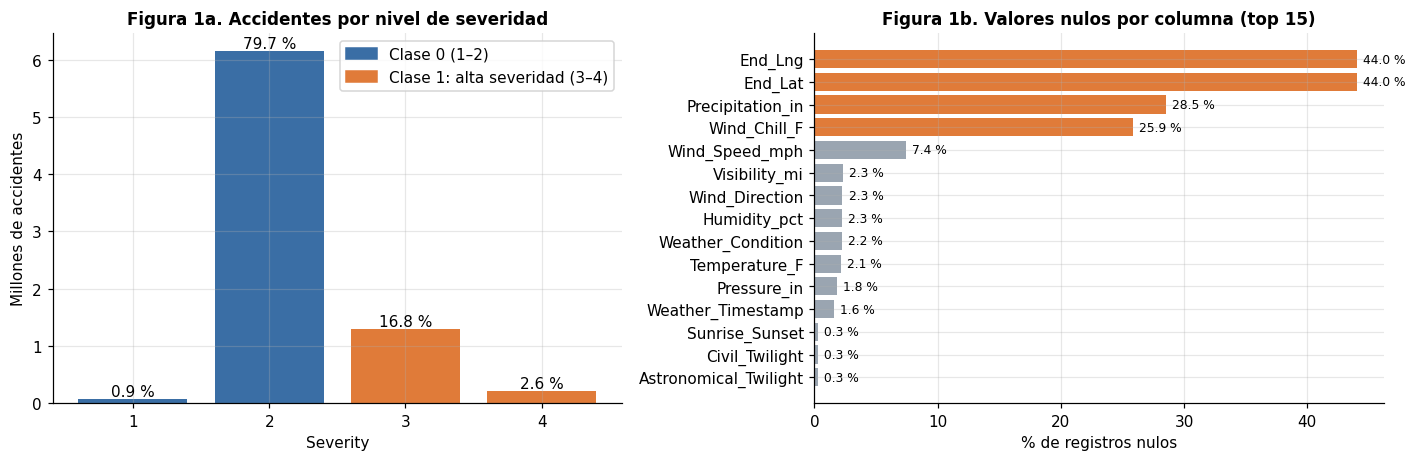

In [ ]:
from matplotlib.patches import Patch
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))

ax[0].bar(sev["Severity"].astype(str), sev["count"] / 1e6, color=[AZUL, AZUL, NARANJA, NARANJA])
for x, (c, p) in enumerate(zip(sev["count"], sev["pct"])):
    ax[0].text(x, c / 1e6, f"{p:.1f} %", ha="center", va="bottom")
ax[0].set(title="Figura 1a. Accidentes por nivel de severidad", xlabel="Severity", ylabel="Millones de accidentes")
ax[0].legend(handles=[Patch(color=AZUL, label="Clase 0 (1–2)"), Patch(color=NARANJA, label="Clase 1: alta severidad (3–4)")])

top_nulos = nulos.sort_values("% nulos", ascending=False).head(15).iloc[::-1]
ax[1].barh(top_nulos.index, top_nulos["% nulos"], color=[NARANJA if v > 20 else GRIS for v in top_nulos["% nulos"]])
for y, v in enumerate(top_nulos["% nulos"]):
    ax[1].text(v + 0.5, y, f"{v:.1f} %", va="center", fontsize=8)
ax[1].set(title="Figura 1b. Valores nulos por columna (top 15)", xlabel="% de registros nulos")
plt.tight_layout(); plt.show()

- **(a) Desbalance:** el nivel 2 concentra el 79.67 % de los accidentes. Los niveles 3 (16.81 %) y 4 (2.65 %) suman 19.46 %, que es la
  proporción de la clase positiva. El nivel 1 (0.87 %) es casi inexistente. Por eso:
  - El problema se planteó como binario (alta vs. no alta severidad), en lugar de 4 clases con una casi vacía.
  - El modelo se entrena con pesos por clase.
  - La accuracy no sirve como métrica principal
- **(b) Nulos:**
  - `End_Lat` y `End_Lng` (44 %) se descartan de todos modos porque se conocen después del accidente, lo que genera fuga de información.
  - `Precipitation_in` (28.5 %) y `Wind_Chill_F` (25.9 %) no se usan como predictores, ya que imputar más de una cuarta parte de los valores
    introduciría mucho ruido, y la sensación térmica es redundante con la temperatura y el viento.
  - `Wind_Speed_mph` (7.4 %) y el resto de las variables de clima sí se usan; sus nulos se imputan con la mediana dentro del pipeline.

**Decisión de modelado:** convertir el problema en clasificación binaria
`High_Severity = 1` si `Severity ∈ {3, 4}`, `0` si `Severity ∈ {1, 2}`.

**Variables que se excluyen para evitar fuga de información:**
`End_Time`, `End_Lat/Lng`, `Distance_mi` y `Description` solo se conocen después de que el accidente afecta la vía
y están directamente ligadas a cómo se asigna la severidad. `Source` también se excluye porque cada proveedor
etiqueta la severidad de forma distinta.

## 3. Limpieza y ingeniería de variables
- **Tiempo:** de `Start_Time` se extraen año, mes, día de la semana, hora y fin de semana.
- **Clima:** `Weather_Condition` tiene >100 valores de texto; se agrupan en 8 categorías.
- **Vía:** las 13 banderas booleanas (Junction, Traffic_Signal, Crossing…) se convierten a 0/1.
- **Nulos numéricos:** se imputan con la mediana. Los nulos en categóricas se marcan como `"Unknown"`.

In [ ]:
POI = ["Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway",
       "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal", "Turning_Loop"]

wc = F.lower(F.coalesce(F.col("Weather_Condition"), F.lit("")))
weather_group = (F.when(wc.rlike("thunder|t-storm|tornado|squall"), "Thunderstorm")
                  .when(wc.rlike("snow|sleet|ice|hail|wintry|freezing"), "Snow/Ice")
                  .when(wc.rlike("rain|drizzle|shower"), "Rain")
                  .when(wc.rlike("fog|mist|haze|smoke|dust|sand"), "Fog/Low visibility")
                  .when(wc.rlike("cloud|overcast"), "Cloudy")
                  .when(wc.rlike("clear|fair"), "Clear")
                  .when(wc == "", "Unknown")
                  .otherwise("Other"))

ts = F.to_timestamp(F.substring("Start_Time", 1, 19))   # algunos registros traen nanosegundos

df = (df_raw
      .withColumn("ts", ts)
      .filter(F.col("ts").isNotNull() & F.col("Severity").isNotNull())
      .withColumn("High_Severity", (F.col("Severity") >= 3).cast(IntegerType()))
      .withColumn("Year", F.year("ts"))
      .withColumn("Month", F.month("ts"))
      .withColumn("DayOfWeek", F.dayofweek("ts"))          # 1 = domingo
      .withColumn("Hour", F.hour("ts"))
      .withColumn("Is_Weekend", F.col("DayOfWeek").isin(1, 7).cast(IntegerType()))
      .withColumn("Weather_Group", weather_group)
      .withColumn("Sunrise_Sunset", F.coalesce("Sunrise_Sunset", F.lit("Unknown")))
      .withColumn("State", F.coalesce("State", F.lit("Unknown"))))

for c in POI:
    df = df.withColumn(c, F.col(c).cast("boolean").cast(IntegerType()))

df = df.cache()
with medir("Limpieza, variables y caché"):
    n_df = df.count()
print(f"Registros limpios: {n_df:,} | Particiones: {df.rdd.getNumPartitions()} | Almacenamiento: {df.storageLevel}")
df.groupBy("High_Severity").count().show()

[Limpieza, variables y caché] 163.1 s | 3 jobs | 4 etapas | 47 tareas
Registros limpios: 7,728,394 | Particiones: 23 | Almacenamiento: Disk Memory Deserialized 1x Replicated
+-------------+-------+
|High_Severity|  count|
+-------------+-------+
|            0|6224347|
|            1|1504047|
+-------------+-------+



### 3.1 Deriva del etiquetado por año y por fuente
En la primera ejecución del notebook, `Year` concentró **≈ 45 % de la importancia** del Random Forest, muy por encima
de cualquier variable de clima o de la vía. El porcentaje de accidentes de alta severidad
cambia de forma marcada entre años y entre fuentes, y la explicación más probable es que cambió quién reportaba y con qué criterio, no que los accidentes
se volvieran más o menos graves.

Usar `Year` como predictor hace que el modelo aprenda el criterio de etiquetado de cada periodo (el mismo problema por el que
se excluye `Source`) y además no sirve para accidentes futuros.

**Decisión: se excluye `Year` de las variables del modelo.** Se conserva `Month` (estacionalidad) y `Year` sigue disponible
para el tablero de Tableau.

In [ ]:
pct = F.round(F.avg("High_Severity") * 100, 1).alias("Pct_Alta_Severidad")
with medir("EDA: deriva por año y fuente"):
    anio = df.groupBy("Year").agg(F.count("*").alias("Accidentes"), pct).orderBy("Year").toPandas()
    fuente = df.groupBy("Source").agg(F.count("*").alias("Accidentes"), pct).orderBy("Source").toPandas()
print("Alta severidad por año:");    print(anio.to_string(index=False))
print("\nAlta severidad por fuente:"); print(fuente.to_string(index=False))

[EDA: deriva por año y fuente] 3.5 s | 8 jobs | 16 etapas | 52 tareas
Alta severidad por año:
 Year  Accidentes  Pct_Alta_Severidad
 2016      410821                34.2
 2017      718093                35.6
 2018      893426                35.6
 2019      954303                27.9
 2020     1178913                18.4
 2021     1563753                11.4
 2022     1762452                 6.9
 2023      246633                 2.9

Alta severidad por fuente:
 Source  Accidentes  Pct_Alta_Severidad
Source1     4325632                 8.1
Source2     3305373                33.9
Source3       97389                31.7


El porcentaje de alta severidad cae de ~35 % (2016–2018) a 6.9 % en 2022 y 2.9 % en 2023, y difiere
por fuente: 8.1 % en `Source1` contra 33.9 % en `Source2`. Una caída de 12 veces en cinco años no es creíble como cambio real
en la gravedad de los accidentes, y la diferencia entre fuentes muestra que la etiqueta depende de quién la asigna.
Esto confirma que `Year` y `Source` deben quedar fuera del modelo, y también anticipa un límite, ya que con estas variables, accidentes
en condiciones parecidas pueden tener etiquetas distintas según el periodo, lo que limita la precisión que cualquier modelo puede alcanzar.

#### Figura 2. Deriva del etiquetado
El panel a combina dos escalas: las barras grises son el número de accidentes registrados cada año (eje izquierdo) y la línea naranja
es el porcentaje de esos accidentes con alta severidad (eje derecho). El panel b compara el porcentaje de alta severidad entre las tres
fuentes de datos.

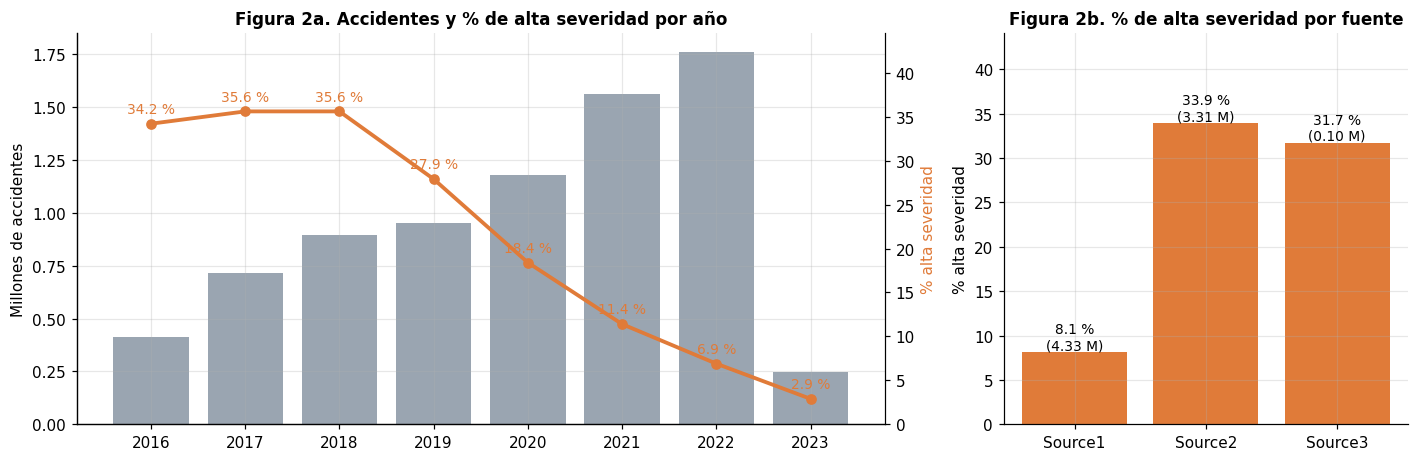

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [2, 1]})
x = anio["Year"].astype(str)
ax[0].bar(x, anio["Accidentes"] / 1e6, color=GRIS)
ax[0].set(title="Figura 2a. Accidentes y % de alta severidad por año", ylabel="Millones de accidentes")
ax2 = ax[0].twinx(); ax2.spines["right"].set_visible(True); ax2.grid(False)
ax2.plot(x, anio["Pct_Alta_Severidad"], color=NARANJA, marker="o", lw=2.5)
for xi, v in zip(x, anio["Pct_Alta_Severidad"]):
    ax2.annotate(f"{v:.1f} %", (xi, v), textcoords="offset points", xytext=(0, 7), ha="center", color=NARANJA, fontsize=9)
ax2.set_ylim(0, max(anio["Pct_Alta_Severidad"]) * 1.25); ax2.set_ylabel("% alta severidad", color=NARANJA)

ax[1].bar(fuente["Source"], fuente["Pct_Alta_Severidad"], color=NARANJA)
for xi, (v, n) in enumerate(zip(fuente["Pct_Alta_Severidad"], fuente["Accidentes"])):
    ax[1].text(xi, v, f"{v:.1f} %\n({n/1e6:.2f} M)", ha="center", va="bottom", fontsize=9)
ax[1].set(title="Figura 2b. % de alta severidad por fuente", ylabel="% alta severidad", ylim=(0, max(fuente["Pct_Alta_Severidad"]) * 1.3))
plt.tight_layout(); plt.show()

- **(a)** Las dos series van en direcciones opuestas:
  - El volumen de registros crece cada año, de 0.41 M en 2016 a 1.76 M en 2022. 2023 solo incluye hasta marzo.
  - El porcentaje de alta severidad cae de ~35 % (2016–2018) a 18.4 % en 2020, 6.9 % en 2022 y 2.9 % en 2023.

  Si los accidentes graves fueran un fenómeno estable, su porcentaje no debería caer 12 veces en siete años. Lo que cambió fue la
  cobertura y el criterio con el que se asignaba la severidad.
- **(b)** `Source2` etiqueta como alta severidad al 33.9 % de sus accidentes; `Source1`, que aporta más registros (4.33 M), solo al 8.1 %.
  La misma etiqueta depende de quién la asigna.
- **Consecuencia para el modelo:** `Year` y `Source` predicen la etiqueta muy bien, pero por el criterio de etiquetado, no por las
  condiciones del accidente. Por eso se excluyen. El ruido que esta deriva deja en la etiqueta limita la precisión que puede alcanzar
  cualquier modelo.

### 3.2 Relación de las variables con la severidad
Antes de entrenar, se revisa qué variables muestran diferencias entre accidentes graves y no graves. Todas las agregaciones de las
figuras 3, 4 y 6 se calculan con Spark sobre los 7.7 M de registros. La figura 5 usa una muestra aleatoria del 2 %.

#### Figura 3. Alta severidad según los elementos de la vía
Para cada una de las 13 banderas de la vía se compara el porcentaje de alta severidad de los accidentes con ese elemento cercano
(punto naranja) contra los accidentes sin él (punto gris). La línea punteada es el promedio general. A la derecha se indica
qué porcentaje de todos los accidentes tiene el elemento; las banderas que casi nunca aparecen tienen poca influencia aunque su diferencia sea grande.

[EDA: elementos de la vía] 3.8 s | 2 jobs | 3 etapas | 24 tareas
       Elemento  % accidentes con el elemento  % alta sev. (con)  % alta sev. (sin)
   Turning_Loop                          0.00                NaN              19.46
     Roundabout                          0.00               4.42              19.46
           Stop                          2.77               6.22              19.84
        Amenity                          1.25               6.29              19.63
       Crossing                         11.31               7.04              21.04
        Station                          2.61               7.51              19.78
 Traffic_Signal                         14.80               9.51              21.19
           Bump                          0.05               9.56              19.47
        No_Exit                          0.25              11.28              19.48
Traffic_Calming                          0.10              12.52              19.47
        Rai

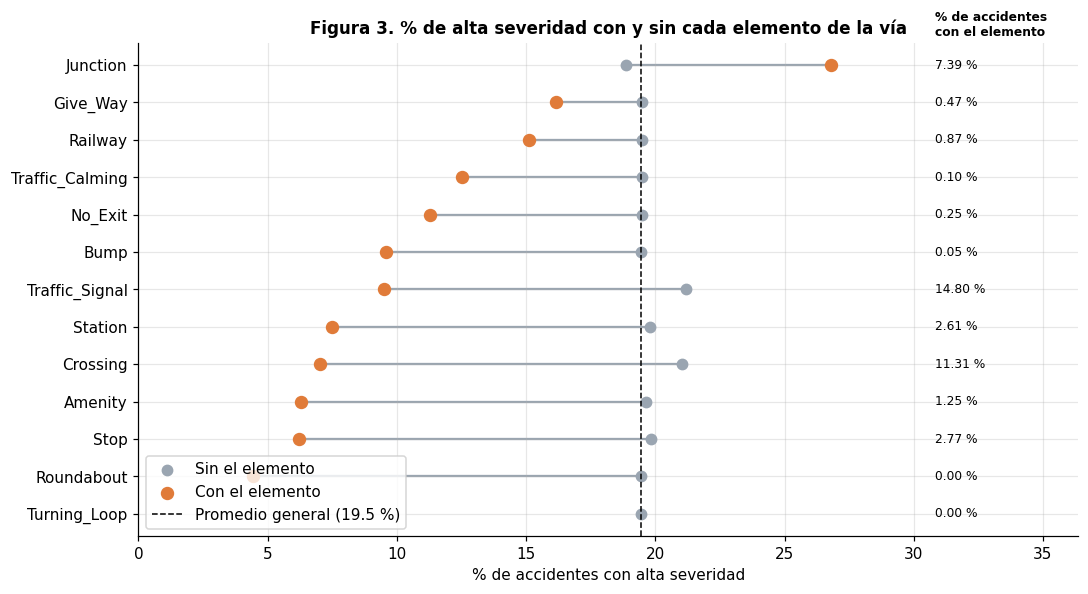

In [ ]:
with medir("EDA: elementos de la vía"):
    r = df.agg(F.count("*").alias("N"), F.sum("High_Severity").alias("P"),
               *[F.sum(c).alias(f"n_{c}") for c in POI],
               *[F.sum(F.col(c) * F.col("High_Severity")).alias(f"p_{c}") for c in POI]).first()

filas = []
for c in POI:
    n_con, pos_con = r[f"n_{c}"] or 0, r[f"p_{c}"] or 0
    filas.append({"Elemento": c, "% accidentes con el elemento": n_con / r["N"] * 100,
                  "% alta sev. (con)": pos_con / n_con * 100 if n_con else np.nan,
                  "% alta sev. (sin)": (r["P"] - pos_con) / (r["N"] - n_con) * 100})
poi = pd.DataFrame(filas).sort_values("% alta sev. (con)", na_position="first").reset_index(drop=True)
tasa_global = r["P"] / r["N"] * 100
print(poi.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5.5))
for y, fila in poi.iterrows():
    ax.plot([fila["% alta sev. (sin)"], fila["% alta sev. (con)"]], [y, y], color=GRIS, lw=1.5, zorder=1)
ax.scatter(poi["% alta sev. (sin)"], poi.index, color=GRIS, s=45, label="Sin el elemento", zorder=2)
ax.scatter(poi["% alta sev. (con)"], poi.index, color=NARANJA, s=60, label="Con el elemento", zorder=3)
ax.axvline(tasa_global, ls="--", color="k", lw=1, label=f"Promedio general ({tasa_global:.1f} %)")
ax.set_yticks(poi.index, poi["Elemento"])
xmax = np.nanmax(poi[["% alta sev. (con)", "% alta sev. (sin)"]].values) * 1.15
for y, v in enumerate(poi["% accidentes con el elemento"]):
    ax.text(xmax, y, f"{v:.2f} %", va="center", fontsize=8)
ax.text(xmax, len(poi) - 0.3, "% de accidentes\ncon el elemento", fontsize=8, va="bottom", fontweight="bold")
ax.set(title="Figura 3. % de alta severidad con y sin cada elemento de la vía", xlabel="% de accidentes con alta severidad", xlim=(0, xmax * 1.18))
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

- **Casi todos los elementos de la vía se asocian con menos accidentes graves.** Los que más influyen son los más frecuentes:
  - `Traffic_Signal` (14.8 % de los accidentes): 9.5 % de alta severidad con semáforo cercano contra 21.2 % sin él.
  - `Crossing` (11.3 %): 7.0 % contra 21.0 %.
  - `Stop` (2.8 %), `Station` (2.6 %) y `Amenity` (1.3 %): entre 6.2 % y 7.5 %, menos de la mitad que sin ellos.

  Son elementos de calles urbanas, donde el tráfico es lento y un accidente afecta poco la circulación.
- **La excepción es `Junction`** (7.4 % de los accidentes): 26.8 % de alta severidad contra 18.9 %. Según la documentación del dataset, esta bandera marca rampas, entradas y salidas de autopistas. Ahí un accidente bloquea carriles de alta velocidad.
- **Elementos raros:** `Roundabout`, `Bump`, `Traffic_Calming` y `No_Exit` aparecen en menos del 0.3 % de los accidentes. Aunque algunas diferencias
  son grandes, afectan a tan pocos registros que casi no influyen en el modelo.
  `Turning_Loop` nunca aparece en los datos (siempre es falso), por eso no tiene punto naranja.

#### Figura 4. Volumen y alta severidad por hora y día de la semana
Las barras grises son el número de accidentes (eje izquierdo) y la línea naranja el porcentaje de alta severidad (eje derecho).
Así se distingue cuándo ocurren más accidentes de cuándo ocurren accidentes más graves, que no es lo mismo.

[EDA: hora y día de la semana] 2.3 s | 8 jobs | 16 etapas | 52 tareas


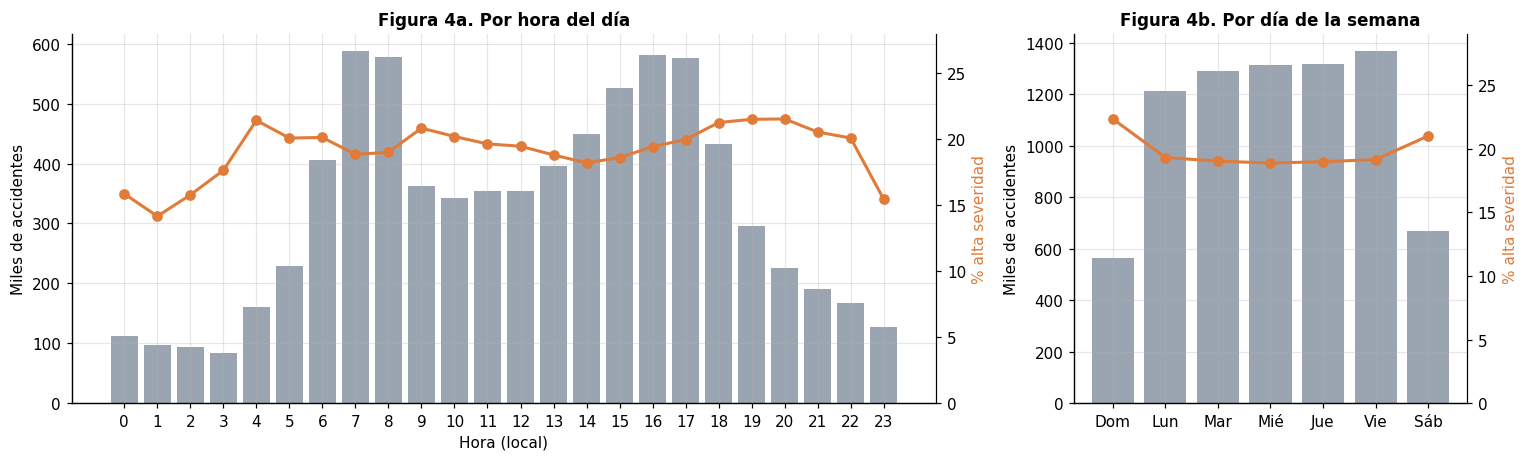

 Hour  Accidentes  Pct
    0      112378 15.8
    1       97071 14.1
    2       93227 15.8
    3       83863 17.6
    4      159852 21.4
    5      228182 20.1
    6      405837 20.1
    7      587472 18.8
    8      577576 19.0
    9      363034 20.8
   10      342706 20.2
   11      355040 19.6
   12      355001 19.4
   13      396445 18.8
   14      448846 18.2
   15      525855 18.6
   16      581969 19.4
   17      576015 20.0
   18      432042 21.2
   19      295121 21.5
   20      225226 21.5
   21      191452 20.5
   22      167645 20.1
   23      126539 15.4
 DayOfWeek  Accidentes  Pct Dia
         1      562744 22.3 Dom
         2     1210921 19.3 Lun
         3     1290929 19.0 Mar
         4     1312389 18.9 Mié
         5     1316229 19.0 Jue
         6     1366499 19.1 Vie
         7      668683 21.0 Sáb


In [ ]:
with medir("EDA: hora y día de la semana"):
    hora = df.groupBy("Hour").agg(F.count("*").alias("Accidentes"), (F.avg("High_Severity") * 100).alias("Pct")).orderBy("Hour").toPandas()
    dia = df.groupBy("DayOfWeek").agg(F.count("*").alias("Accidentes"), (F.avg("High_Severity") * 100).alias("Pct")).orderBy("DayOfWeek").toPandas()
DIAS = ["Dom", "Lun", "Mar", "Mié", "Jue", "Vie", "Sáb"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [2.2, 1]})
for a, d, etiquetas, titulo in [(ax[0], hora, hora["Hour"].astype(str), "Figura 4a. Por hora del día"),
                                 (ax[1], dia, [DIAS[i - 1] for i in dia["DayOfWeek"]], "Figura 4b. Por día de la semana")]:
    a.bar(etiquetas, d["Accidentes"] / 1e3, color=GRIS)
    a.set(title=titulo, ylabel="Miles de accidentes")
    a2 = a.twinx(); a2.spines["right"].set_visible(True); a2.grid(False)
    a2.plot(etiquetas, d["Pct"], color=NARANJA, marker="o", lw=2)
    a2.set_ylim(0, d["Pct"].max() * 1.3); a2.set_ylabel("% alta severidad", color=NARANJA)
ax[0].set_xlabel("Hora (local)")
plt.tight_layout(); plt.show()
print(hora.assign(Pct=hora["Pct"].round(1)).to_string(index=False))
print(dia.assign(Dia=[DIAS[i - 1] for i in dia["DayOfWeek"]], Pct=dia["Pct"].round(1)).to_string(index=False))

- **Volumen (barras):**
  - Hay dos picos diarios en las horas de traslado: 7–8 h y 16–17 h. El mínimo es a las 3 h.
  - Entre semana ocurren entre 1.21 y 1.37 M accidentes por día; en fin de semana, la mitad.

- **% de alta severidad (línea):** se mueve en un rango estrecho (14–22 %) y no sigue al volumen:
  - Las horas pico no son las más graves.
  - Los porcentajes más altos están a las 4 h (21.4 %) y de 18 a 20 h (21.2–21.5 %). Los más bajos, de 23 a 2 h (14.1–15.8 %).
  - El fin de semana tiene más proporción de graves.
  Una explicación posible es que con menos congestión aumenta la proporción de accidentes a mayor velocidad o en autopistas, que bloquean más la vía.
- Para el modelo, estas diferencias son pequeñas. Por eso `Hour` y `DayOfWeek` no entran al top 15 de
  importancia y su correlación con `High_Severity` es casi nula. La hora determina cuántos accidentes ocurren, no qué tan graves son.

#### Figura 5. Variables de clima según la clase
Cada panel compara la distribución de una variable de clima entre accidentes no graves (gris) y graves (naranja). La caja va del
percentil 25 al 75, la línea interior es la mediana y los bigotes cubren el resto de los datos sin valores extremos (que se omiten para
que la escala sea legible). Si las cajas se superponen casi por completo, la variable distingue poco entre clases por sí sola.

[EDA: muestra del 2 % para distribuciones] 2.9 s | 1 jobs | 1 etapas | 23 tareas
Filas en la muestra: 154,626


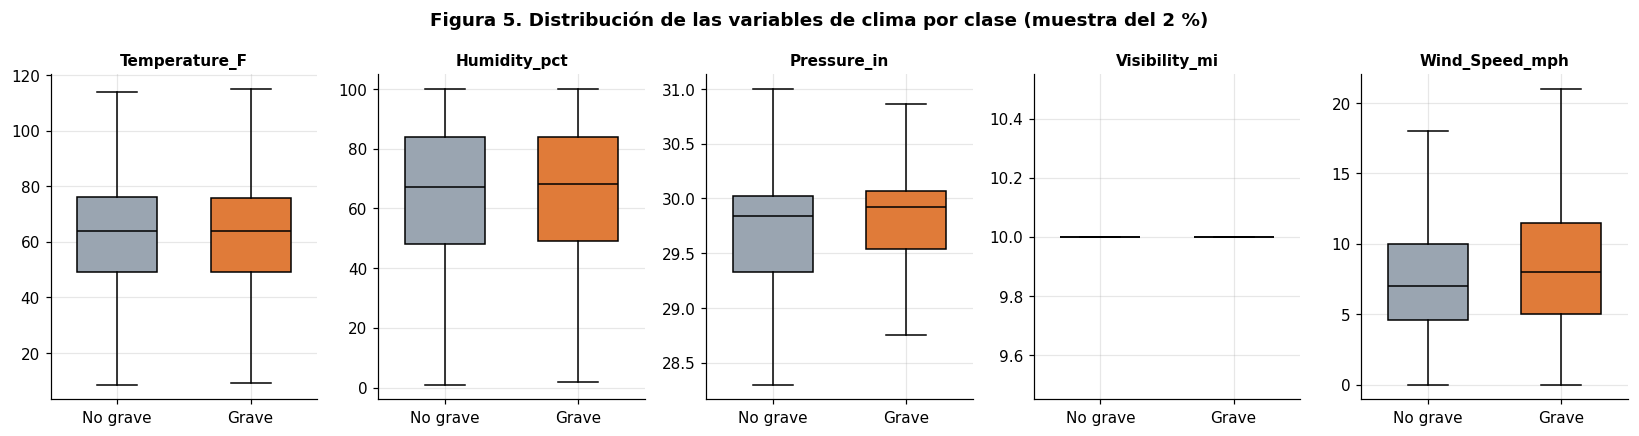

Medianas por clase:
               Temperature_F  Humidity_pct  Pressure_in  Visibility_mi  \
High_Severity                                                            
No grave                64.0          67.0        29.84           10.0   
Grave                   64.0          68.0        29.92           10.0   

               Wind_Speed_mph  
High_Severity                  
No grave                  7.0  
Grave                     8.0  


In [ ]:
VARS_CLIMA = ["Temperature_F", "Humidity_pct", "Pressure_in", "Visibility_mi", "Wind_Speed_mph"]
with medir("EDA: muestra del 2 % para distribuciones"):
    muestra = df.select(VARS_CLIMA + ["High_Severity"]).sample(fraction=0.02, seed=42).toPandas()
print(f"Filas en la muestra: {len(muestra):,}")

fig, ax = plt.subplots(1, len(VARS_CLIMA), figsize=(15, 4))
for a, v in zip(ax, VARS_CLIMA):
    datos = [muestra.loc[muestra["High_Severity"] == k, v].dropna() for k in (0, 1)]
    bp = a.boxplot(datos, tick_labels=["No grave", "Grave"], showfliers=False, patch_artist=True, widths=0.6,
                   medianprops={"color": "k"})
    for caja, color in zip(bp["boxes"], [GRIS, NARANJA]):
        caja.set_facecolor(color)
    a.set_title(v, fontsize=10)
fig.suptitle("Figura 5. Distribución de las variables de clima por clase (muestra del 2 %)", fontweight="bold")
plt.tight_layout(); plt.show()
print("Medianas por clase:")
print(muestra.groupby("High_Severity")[VARS_CLIMA].median().rename(index={0: "No grave", 1: "Grave"}).round(2))

- **Temperatura y humedad:** las cajas son prácticamente idénticas. Por sí solas no distinguen
  accidentes graves de no graves.
- **Visibilidad:** la caja se reduce a una línea en 10 millas. Al menos el 75 % de los registros tiene exactamente 10 mi, el máximo que reportan muchas
  estaciones. La variable solo aporta información en la minoría de casos con visibilidad reducida.
- **Viento:** es la diferencia más visible. Los accidentes graves tienen mediana de 8 mph contra 7, y su caja llega más arriba. Aun así, la diferencia es pequeña.
- **Presión:** los graves tienen una presión ligeramente más alta y menos valores bajos. La presión registrada depende
  de la altitud de la estación, y la figura 6 muestra que se correlaciona con la latitud y la longitud. Por eso esta diferencia refleja
  en parte dónde ocurre el accidente, no solo el clima.

Las variables de clima casi no separan las clases por sí solas. Que `Wind_Speed_mph` y `Pressure_in`
  aparezcan arriba en la importancia del Random Forest se explica más por su combinación con otras variables, su relación con la ubicación
  y el sesgo de la importancia por impureza hacia variables continuas, que por un efecto directo grande.

#### Figura 6. Matriz de correlación
Coeficiente de correlación de Pearson entre las variables numéricas y la variable objetivo (`High_Severity`, última fila), calculado
con `pyspark.ml.stat.Correlation` sobre todos los registros sin nulos. El color va de azul (correlación negativa) a rojo (positiva).
Sirve para dos cosas:
1. Ver si alguna variable tiene relación lineal fuerte con la severidad.
2. Detectar variables redundantes entre sí (multicolinealidad), que afectan sobre todo a la regresión logística.

Una correlación cercana a 0 no descarta relaciones no lineales, que el Random Forest sí puede aprovechar.

[EDA: matriz de correlación] 23.5 s | 4 jobs | 6 etapas | 56 tareas


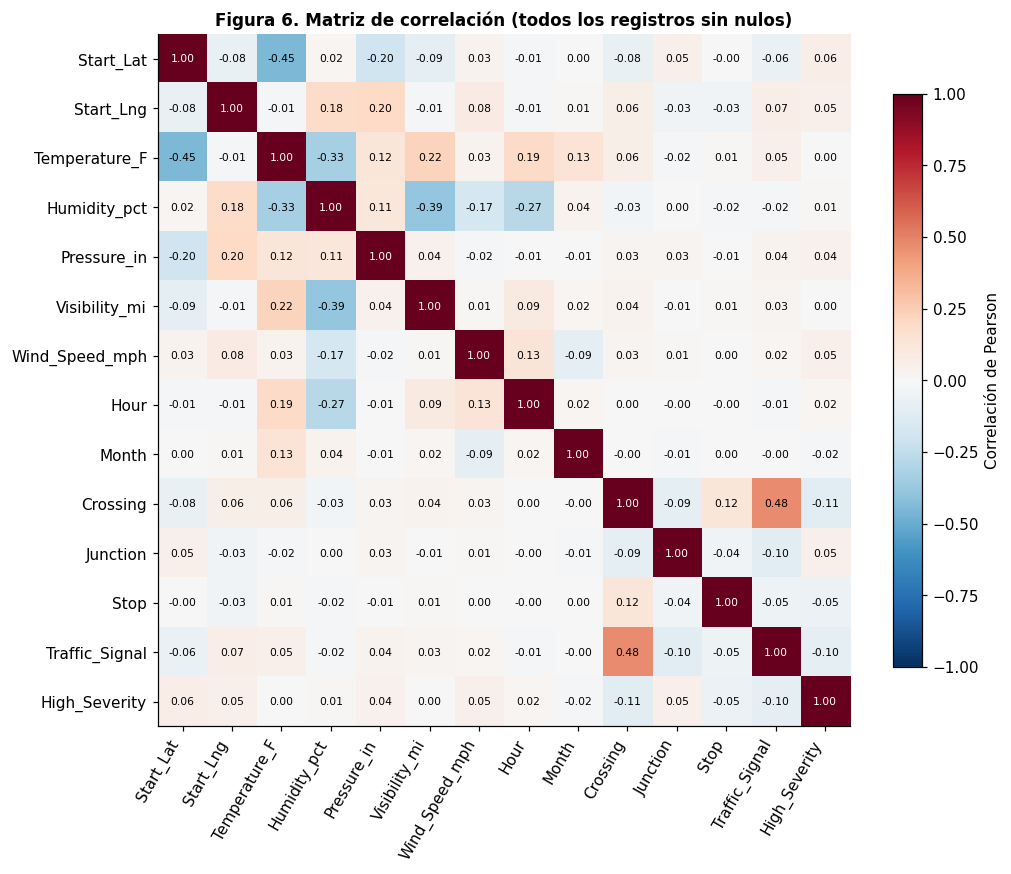

Correlación de cada variable con High_Severity:
Crossing         -0.109
Traffic_Signal   -0.100
Stop             -0.055
Month            -0.019
Visibility_mi     0.001
Temperature_F     0.003
Humidity_pct      0.011
Hour              0.019
Pressure_in       0.045
Wind_Speed_mph    0.048
Start_Lng         0.048
Junction          0.050
Start_Lat         0.065


In [ ]:
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler
CORR = ["Start_Lat", "Start_Lng", "Temperature_F", "Humidity_pct", "Pressure_in", "Visibility_mi",
        "Wind_Speed_mph", "Hour", "Month", "Crossing", "Junction", "Stop", "Traffic_Signal", "High_Severity"]
with medir("EDA: matriz de correlación"):
    vec = VectorAssembler(inputCols=CORR, outputCol="v", handleInvalid="skip").transform(df.select(CORR))
    corr = pd.DataFrame(Correlation.corr(vec, "v", "pearson").head()[0].toArray(), index=CORR, columns=CORR)

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(CORR)), CORR, rotation=60, ha="right"); ax.set_yticks(range(len(CORR)), CORR); ax.grid(False)
for i in range(len(CORR)):
    for j in range(len(CORR)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iat[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Correlación de Pearson")
ax.set_title("Figura 6. Matriz de correlación (todos los registros sin nulos)")
plt.tight_layout(); plt.show()
print("Correlación de cada variable con High_Severity:")
print(corr["High_Severity"].drop("High_Severity").sort_values().round(3).to_string())

- **Con la variable objetivo (última fila):** ninguna correlación supera 0.11 en valor absoluto.
  - Las más fuertes son negativas: `Crossing` (−0.11), `Traffic_Signal` (−0.10) y `Stop` (−0.05).
  - Las positivas más altas son `Start_Lat` (0.065), `Junction` (0.050), `Wind_Speed_mph` (0.048), `Start_Lng` (0.048) y `Pressure_in` (0.045).
  - Las de temperatura, visibilidad, humedad, hora y mes son prácticamente cero.

  Que todas sean débiles significa que ninguna variable predice la severidad por sí sola y el modelo depende de combinaciones entre ellas. Esto explica
  por qué el Random Forest, que captura interacciones y relaciones no lineales, supera a la regresión logística.
  
- **Entre predictores:**
  - `Crossing` y `Traffic_Signal` (0.48): suelen aparecer juntos, en intersecciones urbanas con semáforo y cruce peatonal.
  - Latitud y temperatura (−0.45): más al norte, más frío.
  - Humedad con visibilidad (−0.39), temperatura (−0.33) y hora (−0.27): la humedad sube de noche y con lluvia o niebla.
  - Presión con latitud y longitud (−0.20 y +0.20): la presión registrada depende de la ubicación.

  Ninguna pareja supera 0.5 en valor absoluto, así que no hay multicolinealidad grave y no fue necesario eliminar variables.

## 4. Conjuntos de entrenamiento y prueba
- División aleatoria 80 / 20 con `randomSplit` y semilla fija. Con 7.7 M de filas la proporción de clases queda prácticamente
  igual en ambos conjuntos.
- `FRACCION` permite entrenar con una muestra si mi sesión de Colab se queda corta.
- **Desbalance:** se crea una columna de pesos `w` para que ambas clases aporten lo mismo a la función de pérdida.

In [ ]:
FRACCION = 1.0   # usa 0.3 si la sesión se queda sin memoria o tiempo
SEED = 42

NUM = ["Start_Lat", "Start_Lng", "Temperature_F", "Humidity_pct", "Pressure_in",
       "Visibility_mi", "Wind_Speed_mph", "Month", "DayOfWeek", "Hour", "Is_Weekend"] + POI
CAT = ["State", "Weather_Group", "Sunrise_Sunset"]

data = df.select(NUM + CAT + ["High_Severity"]).sample(fraction=FRACCION, seed=SEED)

train, test = data.randomSplit([0.8, 0.2], seed=SEED)

with medir("División train/test y pesos"):
    n = train.count(); n_pos = train.filter("High_Severity = 1").count()
w_pos, w_neg = n / (2 * n_pos), n / (2 * (n - n_pos))
train = train.withColumn("w", F.when(F.col("High_Severity") == 1, w_pos).otherwise(w_neg)).cache()
test = test.cache()

with medir("Caché de train y test"):
    train.count(); n_test = test.count(); pos_test = test.filter("High_Severity = 1").count() / n_test
print(f"Train: {n:,} | Test: {n_test:,} | Total: {n + n_test:,}")
print(f"% positivos -> train: {n_pos/n*100:.2f}% | test: {pos_test*100:.2f}% | peso clase 1: {w_pos:.2f}")

[División train/test y pesos] 21.7 s | 4 jobs | 6 etapas | 48 tareas
[Caché de train y test] 40.8 s | 8 jobs | 11 etapas | 118 tareas
Train: 6,184,251 | Test: 1,544,143 | Total: 7,728,394
% positivos -> train: 19.47% | test: 19.44% | peso clase 1: 2.57


## 5. Modelo con MLlib
Se arma un pipeline para que exactamente las mismas transformaciones se apliquen en entrenamiento y en predicción:

`Imputer` (mediana) → `StringIndexer` → `OneHotEncoder` → `VectorAssembler` → clasificador

Se entrenan dos modelos:
1. **Regresión logística** — línea base simple e interpretable.
2. **Random Forest** — captura relaciones no lineales (p. ej., hora × estado) y entrega importancia de variables.

In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier

NUM_IMP = [c + "_imp" for c in NUM]
imputer  = Imputer(inputCols=NUM, outputCols=NUM_IMP, strategy="median")
indexer  = StringIndexer(inputCols=CAT, outputCols=[c + "_idx" for c in CAT], handleInvalid="keep")
encoder  = OneHotEncoder(inputCols=[c + "_idx" for c in CAT], outputCols=[c + "_ohe" for c in CAT], handleInvalid="keep")
assemble = VectorAssembler(inputCols=NUM_IMP + [c + "_ohe" for c in CAT], outputCol="features")
prep = [imputer, indexer, encoder, assemble]

lr = LogisticRegression(labelCol="High_Severity", featuresCol="features", weightCol="w", maxIter=30)
rf = RandomForestClassifier(labelCol="High_Severity", featuresCol="features", weightCol="w",
                            numTrees=60, maxDepth=12, subsamplingRate=0.8, seed=SEED)

with medir("Entrenamiento: regresión logística"):
    lr_model = Pipeline(stages=prep + [lr]).fit(train)
with medir("Entrenamiento: Random Forest"):
    rf_model = Pipeline(stages=prep + [rf]).fit(train)

print(f"Árboles: {rf_model.stages[-1].getNumTrees} | Nodos totales: {sum(t.numNodes for t in rf_model.stages[-1].trees):,} "
      f"| Variables en el vector: {rf_model.stages[-1].numFeatures}")

[Entrenamiento: regresión logística] 112.7 s | 40 jobs | 78 etapas | 972 tareas
[Entrenamiento: Random Forest] 1474.9 s | 23 jobs | 41 etapas | 700 tareas
Árboles: 60 | Nodos totales: 128,028 | Variables en el vector: 87


## 6. Evaluación con PySpark
Métricas calculadas con los evaluadores de MLlib sobre el conjunto de prueba (datos que el modelo no vio):
- **AUC-ROC:** capacidad de separar clases independiente del umbral (0.5 = azar, 1 = perfecto). Es la métrica principal.
- **AUC-PR:** más informativa con clases desbalanceadas; el valor de referencia de un modelo al azar es la proporción de positivos (~0.19).
- **Precision, Recall y F1 de la clase 1** (alta severidad): describen qué tan bien se detecta la clase que importa.
- **Accuracy y F1 ponderado:** se reportan como referencia

Se agrega un modelo base que siempre predice "no alta severidad" para tener un punto de comparación.

In [ ]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.functions import vector_to_array
import pandas as pd

def p1(col):
    # Probabilidad de la clase 1 a partir del vector "probability" (sin UDF de Python)
    return vector_to_array(F.col(col))[1]

def evaluar(model, nombre):
    pred = model.transform(test).cache()
    b = BinaryClassificationEvaluator(labelCol="High_Severity", rawPredictionCol="rawPrediction")
    m = MulticlassClassificationEvaluator(labelCol="High_Severity", predictionCol="prediction", metricLabel=1.0)
    res = {"Modelo": nombre,
           "AUC-ROC": b.evaluate(pred, {b.metricName: "areaUnderROC"}),
           "AUC-PR":  b.evaluate(pred, {b.metricName: "areaUnderPR"})}
    for k, met in [("Accuracy", "accuracy"), ("F1 ponderado", "f1"),
                   ("Precision clase 1", "precisionByLabel"),
                   ("Recall clase 1", "recallByLabel"),
                   ("F1 clase 1", "fMeasureByLabel")]:
        res[k] = m.evaluate(pred, {m.metricName: met})
    return res, pred

# Modelo base: siempre predice la clase 0
acc0 = 1 - pos_test
res_base = {"Modelo": "Base (siempre clase 0)", "AUC-ROC": 0.5, "AUC-PR": pos_test, "Accuracy": acc0,
            "F1 ponderado": acc0 * (2 * acc0 / (1 + acc0)),
            "Precision clase 1": 0.0, "Recall clase 1": 0.0, "F1 clase 1": 0.0}

with medir("Evaluación: regresión logística"):
    res_lr, pred_lr = evaluar(lr_model, "Regresión logística")
with medir("Evaluación: Random Forest"):
    res_rf, pred_rf = evaluar(rf_model, "Random Forest")
pd.DataFrame([res_base, res_lr, res_rf]).set_index("Modelo").round(4)

[Evaluación: regresión logística] 66.2 s | 14 jobs | 35 etapas | 507 tareas
[Evaluación: Random Forest] 115.3 s | 14 jobs | 35 etapas | 507 tareas


,AUC-ROC,AUC-PR,Accuracy,F1 ponderado,Precision clase 1,Recall clase 1,F1 clase 1
Modelo,,,,,,,
Base (siempre clase 0),0.5000,0.1944,0.8056,0.7189,0.0000,0.0000,0.0000
Regresión logística,0.7018,0.3561,0.6451,0.6811,0.3053,0.6477,0.4150
Random Forest,0.7426,0.4100,0.6413,0.6786,0.3171,0.7328,0.4426


In [ ]:
print("Matriz de confusión — Random Forest (filas = real, columnas = predicho)")
pred_rf.groupBy("High_Severity").pivot("prediction", [0.0, 1.0]).count().orderBy("High_Severity").show()

Matriz de confusión — Random Forest (filas = real, columnas = predicho)
+-------------+------+------+
|High_Severity|   0.0|   1.0|
+-------------+------+------+
|            0|770285|473744|
|            1| 80183|219931|
+-------------+------+------+



- **Capacidad de discriminación:** el Random Forest obtiene AUC-ROC = 0.743 frente a 0.702 de la regresión logística. Ambos están claramente
  por encima del azar (0.5), pero la discriminación es moderada, no alta. En AUC-PR el Random Forest llega a 0.410, poco más del doble
  del valor de referencia (0.194 = proporción de positivos).
- **Comparación entre modelos:** el Random Forest supera a la regresión logística en AUC-ROC, AUC-PR, precisión, recall y F1 de la clase 1
  (sobre todo en recall: 73.3 % contra 64.8 %). Solo pierde en accuracy por 0.4 puntos (0.641 contra 0.645), porque marca más accidentes como graves.
- **Matriz de confusión (Random Forest, umbral 0.5):**
  - Detecta 219,931 de 300,114 accidentes de alta severidad (**recall 73 %**).
  - Marca como graves al 44.9 % de los accidentes, aunque solo el 19.4 % lo es. Por eso, de cada 100 accidentes que marca como graves,
    solo 32 lo son (precisión de la clase 1). Aun así, es 1.6 veces mejor que marcar accidentes al azar (19.4 %).
  - Clasifica erróneamente como graves al 38 % de los accidentes de baja severidad (473,744 falsos positivos).
  - Cuando predice "no grave" acierta el 90.6 % de las veces, osea que es más confiable para descartar que para confirmar.
- **Accuracy:** ambos modelos quedan por debajo del modelo base (0.806). Es la consecuencia esperada de los pesos por clase, que empujan al modelo
  a marcar más accidentes como graves. El modelo base no detecta ningún accidente grave, así que su accuracy no indica un mejor modelo.
- La fila del modelo base usa como AUC los valores de un clasificador sin información (0.5 y la proporción de positivos).

#### Figura 7. Comparación de métricas y matriz de confusión normalizada
El panel a pone lado a lado las métricas de la tabla anterior para los tres modelos. El panel b es la matriz de confusión del
Random Forest normalizada por fila. Cada fila suma 100 % y muestra qué pasa con los accidentes de cada clase real. La diagonal son los
aciertos.

[Figuras: matriz de confusión] 3.1 s | 2 jobs | 3 etapas | 24 tareas


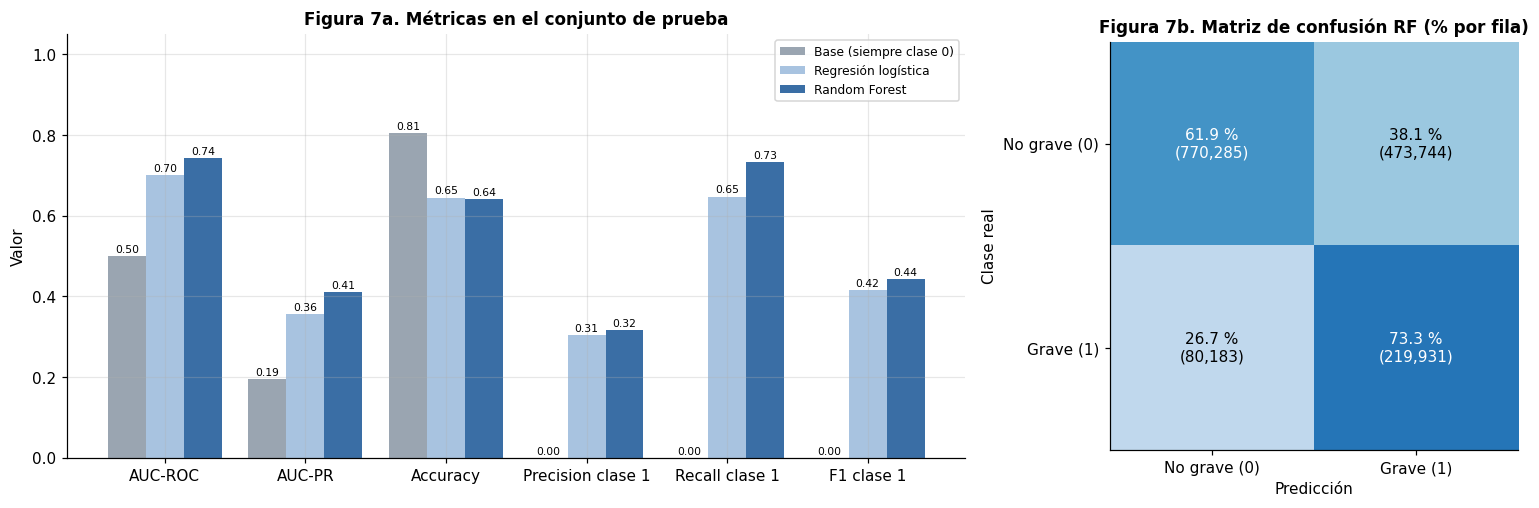

In [ ]:
met = pd.DataFrame([res_base, res_lr, res_rf]).set_index("Modelo")
cols = ["AUC-ROC", "AUC-PR", "Accuracy", "Precision clase 1", "Recall clase 1", "F1 clase 1"]
with medir("Figuras: matriz de confusión"):
    cm = pred_rf.groupBy("High_Severity", "prediction").count().toPandas() \
                .pivot(index="High_Severity", columns="prediction", values="count").fillna(0)
cm_pct = cm.div(cm.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
x = np.arange(len(cols)); w = 0.27
for i, (modelo, color) in enumerate(zip(met.index, [GRIS, AZUL_CLARO, AZUL])):
    vals = met.loc[modelo, cols].astype(float)
    barras = ax[0].bar(x + (i - 1) * w, vals, w, color=color, label=modelo)
    ax[0].bar_label(barras, fmt="%.2f", fontsize=7, padding=1)
ax[0].set_xticks(x, cols); ax[0].set_ylim(0, 1.05)
ax[0].set(title="Figura 7a. Métricas en el conjunto de prueba", ylabel="Valor")
ax[0].legend(loc="upper right", fontsize=8)

ax[1].imshow(cm_pct.values, cmap="Blues", vmin=0, vmax=100); ax[1].grid(False)
etq = ["No grave (0)", "Grave (1)"]
ax[1].set_xticks([0, 1], etq); ax[1].set_yticks([0, 1], etq)
ax[1].set(xlabel="Predicción", ylabel="Clase real", title="Figura 7b. Matriz de confusión RF (% por fila)")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, f"{cm_pct.iat[i, j]:.1f} %\n({int(cm.iat[i, j]):,})", ha="center", va="center",
                   color="white" if cm_pct.iat[i, j] > 50 else "black")
plt.tight_layout(); plt.show()

- **(a)** Hay dos grupos de métricas que se comportan distinto:
  - **Métricas de la clase grave** (AUC-ROC, AUC-PR, precisión, recall, F1): el Random Forest (azul oscuro) supera a la regresión
    logística en todas, y ambos superan al modelo base. La diferencia más grande está en el recall (0.73 contra 0.65).
  - **Accuracy:** el orden se invierte. El modelo base es el más alto (0.81) sin detectar un solo accidente grave. Por eso la accuracy
    no se usa para elegir el modelo.
- **(b)** De los accidentes realmente graves, el modelo detecta el 73.3 % y se le escapa el 26.7 % (80,183 falsos negativos).
  De los no graves, clasifica bien el 61.9 % y marca como graves al 38.1 % (473,744 falsos positivos).
  - Como la clase no grave es cuatro veces más numerosa, ese 38 % produce muchos más errores en números absolutos que el 26.7 % de la clase grave.
  - Por eso la precisión de la clase 1 es baja, ya que la mayoría de las alertas de "grave" son falsas.

#### Figura 8. Curvas ROC y Precision-Recall
Las curvas muestran el desempeño del modelo en todos los umbrales posibles, no solo en 0.5.
Spark agrupa las 1.5 M predicciones de prueba en 500 intervalos de puntaje y cuenta positivos y negativos en cada uno. Las curvas se
obtienen acumulando esos conteos, así que no hace falta traer las predicciones individuales a memoria.
- **(a) ROC:** tasa de verdaderos positivos (recall) contra tasa de falsos positivos. La diagonal punteada es un modelo al azar; mientras
  más se acerque la curva a la esquina superior izquierda, mejor. El área bajo la curva es el AUC-ROC.
- **(b) Precision-Recall:** precisión contra recall. La línea punteada es la proporción de positivos (lo que lograría un modelo al azar).
  Es más exigente que la ROC cuando la clase positiva es minoritaria.

El círculo marca el punto de operación del Random Forest con el umbral por defecto (0.5). La celda también compara el AUC calculado
a partir de los intervalos con el del evaluador de MLlib, para verificar que las curvas son correctas.

[Figuras: curvas ROC y PR] 3.8 s | 4 jobs | 6 etapas | 48 tareas
Verificación (AUC con intervalos vs. evaluador de MLlib):
  Regresión logística  AUC-ROC 0.7018 vs 0.7018 | AUC-PR 0.3561 vs 0.3561
  Random Forest        AUC-ROC 0.7425 vs 0.7426 | AUC-PR 0.4102 vs 0.4100


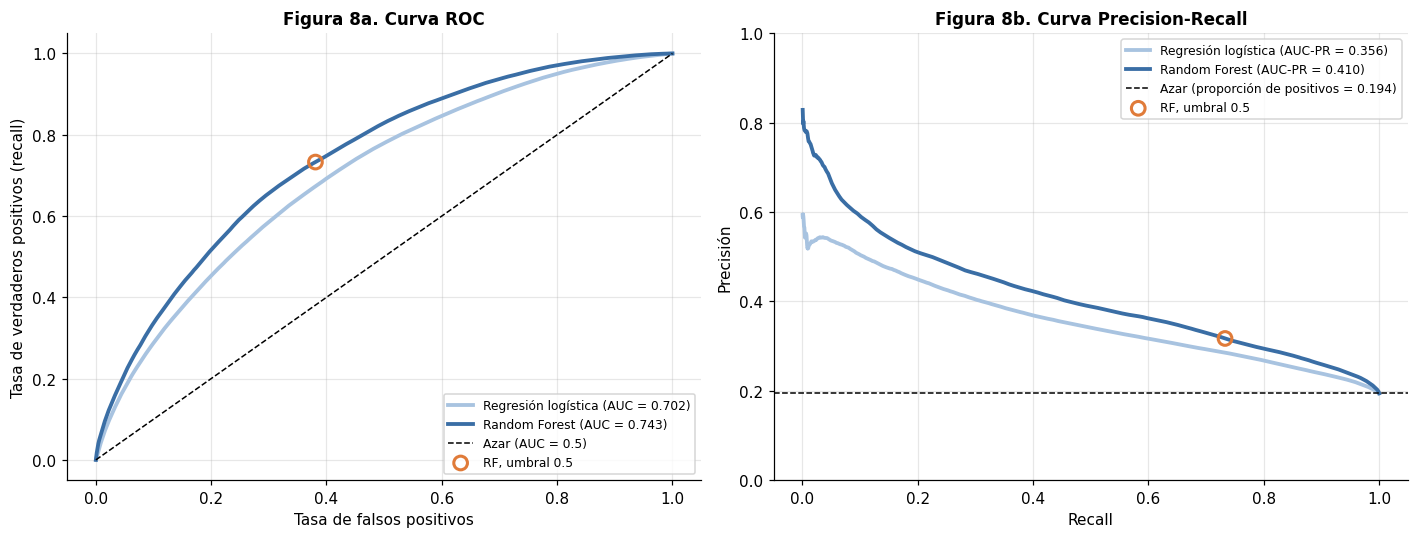

In [ ]:
_trapz = getattr(np, "trapezoid", None) or np.trapz

def curvas(pred, n_bins=500):
    """Curvas ROC/PR a partir de un histograma de puntajes calculado con Spark."""
    b = (pred.select(F.col("High_Severity").alias("y"), p1("probability").alias("p"))
             .withColumn("bin", F.least(F.floor(F.col("p") * n_bins), F.lit(n_bins - 1)).cast("int"))
             .groupBy("bin").agg(F.count("*").alias("n"), F.sum("y").alias("pos"), F.sum("p").alias("suma_p"))
             .toPandas().set_index("bin").reindex(range(n_bins)).fillna(0))
    d = b.iloc[::-1]                                         # de mayor a menor puntaje
    tp = d["pos"].cumsum().values; fp = (d["n"] - d["pos"]).cumsum().values
    tpr, fpr = tp / tp[-1], fp / fp[-1]
    with np.errstate(divide="ignore", invalid="ignore"):
        prec = np.where(tp + fp > 0, tp / (tp + fp), np.nan)
    c = pd.DataFrame({"umbral": d.index.values / n_bins, "fpr": fpr, "tpr": tpr, "precision": prec, "n_pred": tp + fp})
    auc_roc = _trapz(np.r_[0, tpr], np.r_[0, fpr])
    ok = ~np.isnan(prec)
    auc_pr = _trapz(prec[ok], tpr[ok])
    return b, c, auc_roc, auc_pr

with medir("Figuras: curvas ROC y PR"):
    bins_lr, cur_lr, aroc_lr, apr_lr = curvas(pred_lr)
    bins_rf, cur_rf, aroc_rf, apr_rf = curvas(pred_rf)

print("Verificación (AUC con intervalos vs. evaluador de MLlib):")
for nom, ar, ap, res in [("Regresión logística", aroc_lr, apr_lr, res_lr), ("Random Forest", aroc_rf, apr_rf, res_rf)]:
    print(f"  {nom:20s} AUC-ROC {ar:.4f} vs {res['AUC-ROC']:.4f} | AUC-PR {ap:.4f} vs {res['AUC-PR']:.4f}")

op = cur_rf.iloc[(cur_rf["umbral"] - 0.5).abs().argmin()]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c, color, nom, auc in [(cur_lr, AZUL_CLARO, "Regresión logística", res_lr["AUC-ROC"]), (cur_rf, AZUL, "Random Forest", res_rf["AUC-ROC"])]:
    ax[0].plot(np.r_[0, c["fpr"]], np.r_[0, c["tpr"]], color=color, lw=2.5, label=f"{nom} (AUC = {auc:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.5)")
ax[0].scatter(op["fpr"], op["tpr"], s=80, facecolors="none", edgecolors=NARANJA, lw=2, zorder=5, label="RF, umbral 0.5")
ax[0].set(title="Figura 8a. Curva ROC", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall)")
ax[0].legend(loc="lower right", fontsize=8)

for c, color, nom, auc in [(cur_lr, AZUL_CLARO, "Regresión logística", res_lr["AUC-PR"]), (cur_rf, AZUL, "Random Forest", res_rf["AUC-PR"])]:
    v = c[c["n_pred"] >= 200]                                   # se omiten umbrales con muy pocas predicciones
    ax[1].plot(v["tpr"], v["precision"], color=color, lw=2.5, label=f"{nom} (AUC-PR = {auc:.3f})")
ax[1].axhline(pos_test, ls="--", color="k", lw=1, label=f"Azar (proporción de positivos = {pos_test:.3f})")
ax[1].scatter(op["tpr"], op["precision"], s=80, facecolors="none", edgecolors=NARANJA, lw=2, zorder=5, label="RF, umbral 0.5")
ax[1].set(title="Figura 8b. Curva Precision-Recall", xlabel="Recall", ylabel="Precisión", ylim=(0, 1))
ax[1].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

- **(a) ROC:**
  - La curva del Random Forest queda por encima de la regresión logística en todo el rango, no solo en promedio. Para cualquier tasa de falsos
    positivos que se acepte, el Random Forest detecta más accidentes graves. Ambas están claramente separadas de la diagonal del azar.
  - El punto de operación con umbral 0.5 (círculo) está en 38 % de falsos positivos y 73 % de recall. Para detectar tres de cada cuatro accidentes graves,
    el modelo tiene que marcar como graves a más de un tercio de los no graves.
- **(b) Precision-Recall:**
  - El Random Forest también domina. En el extremo izquierdo (los accidentes con puntaje más alto) su precisión llega a ~0.8, contra ~0.55–0.6 de la
    regresión logística.
  - Después la precisión cae rápido: ~0.5 con recall de 0.2 y 0.32 en el punto de operación (recall de 0.73). Siempre queda por encima de la referencia del azar (0.194).

### 6.1 Importancia de variables (Random Forest) — figura 9
Se recuperan los nombres de cada posición del vector `features` (incluyendo cada categoría one-hot) a partir de los metadatos del `VectorAssembler`.

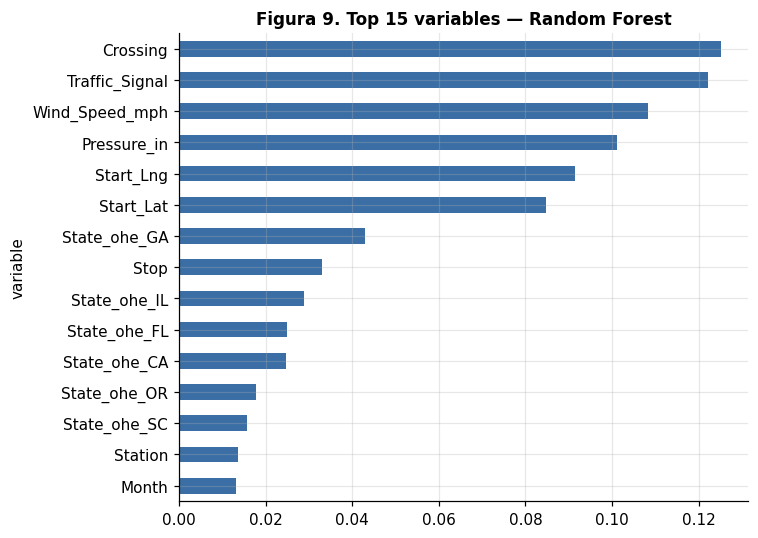

In [ ]:
rf_stage = rf_model.stages[-1]
attrs = pred_rf.schema["features"].metadata["ml_attr"]["attrs"]
nombres = sorted([a for grupo in attrs.values() for a in grupo], key=lambda a: a["idx"])
imp = pd.DataFrame({"variable": [a["name"].replace("_imp", "") for a in nombres],
                    "importancia": rf_stage.featureImportances.toArray()})
top = imp.sort_values("importancia", ascending=False).head(15)

import matplotlib.pyplot as plt
top.iloc[::-1].plot.barh(x="variable", y="importancia", legend=False, figsize=(7, 5), color="#3a6ea5")
plt.title("Figura 9. Top 15 variables — Random Forest"); plt.tight_layout(); plt.show()

- La importancia está repartida, ya que ninguna variable supera el 13 %
- Por grupos, los tres bloques principales son:
  - **Elementos de la vía** (`Crossing` 0.125, `Traffic_Signal` 0.122, `Stop`, `Station`): ≈ 0.29 en total.
  - **Ubicación** (`Start_Lng`, `Start_Lat` y los estados GA, IL, FL, CA, OR y SC): ≈ 0.33.
  - **Clima numérico** (`Wind_Speed_mph`, `Pressure_in`): ≈ 0.21.
- Las variables de tiempo apenas aparecen: solo `Month` (0.013) entra al top 15. `Hour`, `DayOfWeek` y `Weather_Group` no aparecen.
- La importancia indica cuánto usa el modelo cada variable, no si sube o baja la severidad.
- **`Wind_Speed_mph` y `Pressure_in`:** su peso es mayor de lo que el clima justificaría físicamente. Para esto, hay dos razones posibles:
  - La importancia por impureza del Random Forest favorece a las variables continuas con muchos valores distintos.
  - La forma de registrar el clima cambió entre fuentes y periodos (por ejemplo, el viento tiene 7.4 % de nulos), así que estas variables podrían
    funcionar en parte como indicadores indirectos de la fuente.

### 6.2 Efecto del umbral de decisión
MLlib clasifica como 1 cuando la probabilidad es ≥ 0.5. Cambiar el umbral mueve el balance entre detectar más accidentes graves
(recall) y equivocarse menos al marcarlos (precisión). El modelo final conserva 0.5.

In [ ]:
UMBRALES = [0.3, 0.4, 0.5, 0.6, 0.7]
pr = pred_rf.select(F.col("High_Severity").alias("y"), p1("probability").alias("p"))
agg = pr.agg(*[F.sum(((F.col("p") >= t) & (F.col("y") == 1)).cast("int")).alias(f"tp{i}") for i, t in enumerate(UMBRALES)],
             *[F.sum((F.col("p") >= t).cast("int")).alias(f"pp{i}") for i, t in enumerate(UMBRALES)],
             F.sum("y").alias("pos"), F.count("*").alias("n")).first()

filas = []
for i, t in enumerate(UMBRALES):
    tp, pp = agg[f"tp{i}"], agg[f"pp{i}"]
    prec, rec = tp / pp if pp else 0, tp / agg["pos"]
    filas.append({"Umbral": t, "Precision clase 1": prec, "Recall clase 1": rec,
                  "F1 clase 1": 2 * prec * rec / (prec + rec) if prec + rec else 0,
                  "% marcados como alta": pp / agg["n"] * 100})
pd.DataFrame(filas).set_index("Umbral").round(3)

,Precision clase 1,Recall clase 1,F1 clase 1,% marcados como alta
Umbral,,,,
0.3,0.220,0.979,0.360,86.329
0.4,0.260,0.899,0.403,67.279
0.5,0.317,0.733,0.443,44.923
0.6,0.413,0.427,0.420,20.078
0.7,0.686,0.045,0.084,1.266


- Entre los umbrales evaluados, 0.5 obtiene el F1 más alto de la clase 1 (0.443), así que el umbral por defecto es razonable.
- Con 0.6 el modelo marca al 20.1 % de los accidentes, casi la proporción real (19.4 %). Con ese umbral, precisión y recall quedan equilibrados (~0.42 cada uno).
- Con 0.3 detecta el 98 % de los accidentes graves, pero marca al 86 % de todos, así que pierde utilidad práctica.
- De 0.6 a 0.7 el recall cae de 43 % a 4.5 %. Muy pocos accidentes reciben puntajes altos, osea que el modelo rara vez está "seguro".
- La elección depende del uso, ya que para alertas tempranas conviene un umbral bajo (no dejar pasar accidentes graves); para asignar recursos limitados, uno más alto.

#### Figura 10. Umbral, distribución de puntajes y calibración
Tres vistas del puntaje que asigna el Random Forest, calculadas con el mismo histograma distribuido de la figura 8:
- **(a) Métricas contra umbral:** precisión, recall y F1 de la clase grave para cualquier umbral entre 0 y 1 (la tabla anterior solo
  muestra cinco). La línea vertical marca 0.5.
- **(b) Distribución de puntajes por clase:** qué proporción de los accidentes de cada clase recibe cada puntaje. Si las dos
  distribuciones estuvieran separadas, el modelo clasificaría casi sin errores; la zona donde se superponen genera los errores.
- **(c) Calibración:** los accidentes se agrupan por puntaje (intervalos de 0.1) y se compara el puntaje promedio de cada grupo con la
  proporción real de graves. Un modelo calibrado queda sobre la diagonal; si queda por debajo, sus puntajes exageran el riesgo.
  El tamaño de cada punto indica cuántos accidentes hay en el grupo.

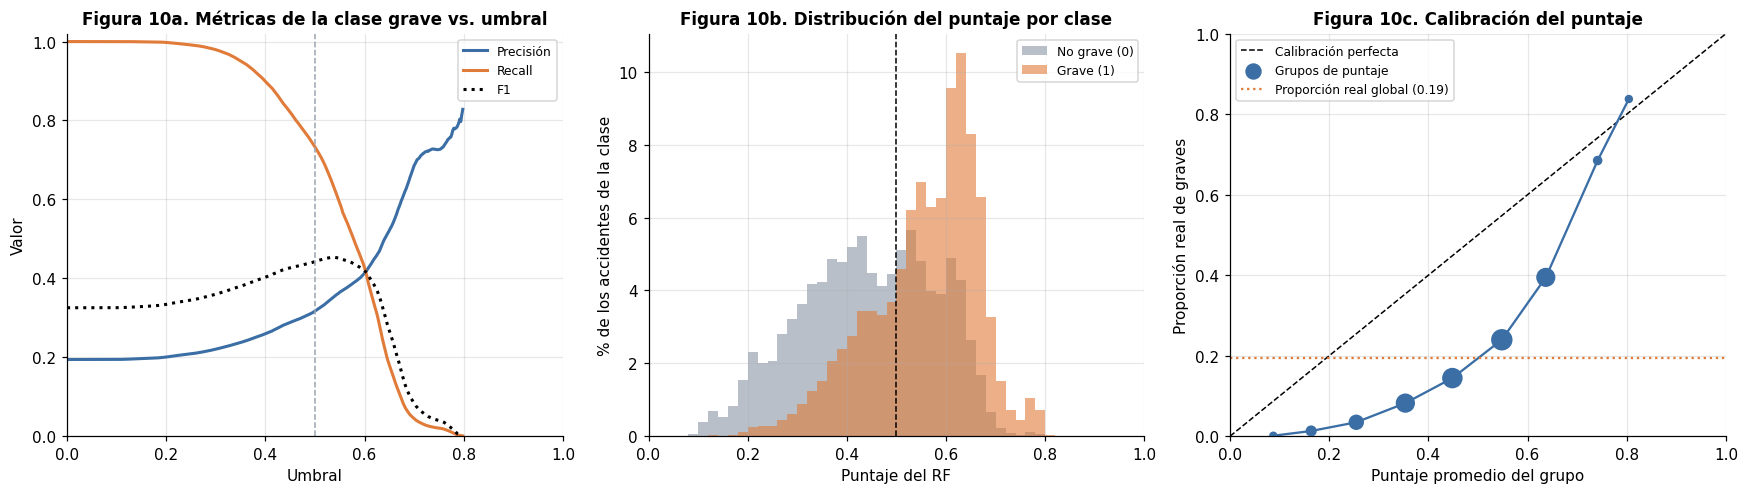

F1 máximo: 0.453 con umbral 0.538 (precisión 0.354, recall 0.631)

Calibración por grupo de puntaje:
intervalo      n  prom_puntaje  tasa_real
  0.0–0.1    869         0.087      0.001
  0.1–0.2  50268         0.164      0.013
  0.2–0.3 159966         0.255      0.035
  0.3–0.4 294151         0.354      0.082
  0.4–0.5 345214         0.448      0.144
  0.5–0.6 383644         0.548      0.240
  0.6–0.7 290480         0.637      0.395
  0.7–0.8  19397         0.741      0.685
  0.8–0.9    154         0.804      0.838


In [ ]:
c = cur_rf[cur_rf["n_pred"] >= 200].dropna().sort_values("umbral")   # umbrales con al menos 200 predicciones
f1 = 2 * c["precision"] * c["tpr"] / (c["precision"] + c["tpr"])
mejor = c.loc[f1.idxmax()]

h = bins_rf.copy(); h["grupo"] = h.index // 10                    # 500 intervalos -> 50 de ancho 0.02
h = h.groupby("grupo")[["n", "pos"]].sum(); h["neg"] = h["n"] - h["pos"]
centros = (h.index + 0.5) * 0.02

cal = bins_rf.copy(); cal["grupo"] = cal.index // 50              # 500 intervalos -> 10 de ancho 0.1
cal = cal.groupby("grupo")[["n", "pos", "suma_p"]].sum().query("n >= 100")   # grupos con al menos 100 accidentes
cal["prom_puntaje"], cal["tasa_real"] = cal["suma_p"] / cal["n"], cal["pos"] / cal["n"]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].plot(c["umbral"], c["precision"], color=AZUL, lw=2, label="Precisión")
ax[0].plot(c["umbral"], c["tpr"], color=NARANJA, lw=2, label="Recall")
ax[0].plot(c["umbral"], f1, color="k", lw=2, ls=":", label="F1")
ax[0].axvline(0.5, color=GRIS, ls="--", lw=1)
ax[0].set(title="Figura 10a. Métricas de la clase grave vs. umbral", xlabel="Umbral", ylabel="Valor", xlim=(0, 1), ylim=(0, 1.02))
ax[0].legend(fontsize=8)

ax[1].bar(centros, h["neg"] / h["neg"].sum() * 100, width=0.02, color=GRIS, alpha=0.7, label="No grave (0)")
ax[1].bar(centros, h["pos"] / h["pos"].sum() * 100, width=0.02, color=NARANJA, alpha=0.6, label="Grave (1)")
ax[1].axvline(0.5, color="k", ls="--", lw=1)
ax[1].set(title="Figura 10b. Distribución del puntaje por clase", xlabel="Puntaje del RF", ylabel="% de los accidentes de la clase", xlim=(0, 1))
ax[1].legend(fontsize=8)

ax[2].plot([0, 1], [0, 1], "k--", lw=1, label="Calibración perfecta")
ax[2].plot(cal["prom_puntaje"], cal["tasa_real"], color=AZUL, lw=1.5)
ax[2].scatter(cal["prom_puntaje"], cal["tasa_real"], s=20 + 600 * cal["n"] / cal["n"].sum(), color=AZUL, zorder=3, label="Grupos de puntaje")
ax[2].axhline(pos_test, color=NARANJA, ls=":", lw=1.5, label=f"Proporción real global ({pos_test:.2f})")
ax[2].set(title="Figura 10c. Calibración del puntaje", xlabel="Puntaje promedio del grupo", ylabel="Proporción real de graves", xlim=(0, 1), ylim=(0, 1))
ax[2].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

print(f"F1 máximo: {f1.max():.3f} con umbral {mejor['umbral']:.3f} (precisión {mejor['precision']:.3f}, recall {mejor['tpr']:.3f})")
print("\nCalibración por grupo de puntaje:")
print(cal.assign(intervalo=[f"{g/10:.1f}–{(g+1)/10:.1f}" for g in cal.index], n=cal["n"].astype(int))
         [["intervalo", "n", "prom_puntaje", "tasa_real"]].round(3).to_string(index=False))

- **(a) Métricas contra umbral:**
  - El F1 alcanza su máximo, 0.453, con umbral 0.538 (precisión 0.354, recall 0.631). Es apenas mejor que el 0.443 de 0.5, así que el umbral por defecto
    está muy cerca del óptimo.
  - La precisión solo supera 0.5 con umbrales por encima de ~0.63, y para entonces el recall ya cayó a cerca de 0.3. Ningún umbral logra a la vez
    precisión y recall altos. El límite está en el modelo, no en el umbral.
- **(b) Distribución de puntajes:**
  - Los accidentes graves se concentran entre 0.5 y 0.7 (pico cerca de 0.63). Los no graves están más repartidos, con la mayoría entre 0.2 y 0.55.
  - Las dos distribuciones se superponen sobre todo entre 0.45 y 0.65. Como hay cuatro veces más accidentes no graves, la parte de su distribución que
    queda arriba de 0.5 (38 % de la clase) produce más errores que aciertos. Ese es el origen de los 474 mil falsos positivos.
- **(c) Calibración:**
  - La curva siempre sube. La proporción real de graves pasa de 0.1 % (puntaje 0–0.1) a 24 % (0.5–0.6), 40 % (0.6–0.7), 69 % (0.7–0.8) y 84 % (0.8–0.9).
    El modelo **ordena bien** el riesgo, a mayor puntaje, más probable es que el accidente sea grave.
  - Pero la curva queda por debajo de la diagonal hasta ~0.75. Un puntaje de 0.45 corresponde a 14 % de graves reales, y uno de 0.55 a 24 %.
    Los puntajes exageran el riesgo, como efecto de los pesos por clase.
  - Los grupos de 0.7 a 0.9 tienen pocos accidentes, así que el último punto, sobre la diagonal, no es representativo.

In [ ]:
# Guardar el modelo (opcional: monta Drive para conservarlo entre sesiones)
from google.colab import drive; drive.mount("/content/drive"); RUTA_MODELO = "/content/drive/MyDrive/rf_us_accidents"
with medir("Guardado del modelo"):
    rf_model.write().overwrite().save(RUTA_MODELO)
print("Modelo guardado en", RUTA_MODELO)

Mounted at /content/drive
[Guardado del modelo] 11.9 s | 14 jobs | 17 etapas | 17 tareas
Modelo guardado en /content/drive/MyDrive/rf_us_accidents


## 7. Exportación para el tablero en Tableau


In [ ]:
import shutil
OUT = "/content/tableau"; os.makedirs(OUT, exist_ok=True)

def exportar(sdf, nombre):
    sdf.toPandas().to_csv(f"{OUT}/{nombre}.csv", index=False)
    print(f"{nombre}.csv  ({sdf.count():,} filas)")

pct_alta = F.round(F.avg("High_Severity") * 100, 2).alias("Pct_Alta_Severidad")

with medir("Exportación de CSV para Tableau"):
    exportar(df.groupBy("State").agg(F.count("*").alias("Accidentes"), pct_alta,
                                     F.round(F.avg("Temperature_F"), 1).alias("Temp_Prom_F"),
                                     F.round(F.avg("Visibility_mi"), 2).alias("Visibilidad_Prom_mi")), "por_estado")
    exportar(df.withColumn("Fecha", F.date_format(F.trunc("ts", "month"), "yyyy-MM-dd"))
               .groupBy("Fecha", "Severity").count().withColumnRenamed("count", "Accidentes"), "por_tiempo")
    exportar(df.groupBy("DayOfWeek", "Hour").agg(F.count("*").alias("Accidentes"), pct_alta), "hora_dia")
    exportar(df.groupBy("Weather_Group").agg(F.count("*").alias("Accidentes"), pct_alta), "por_clima")
    exportar(df.groupBy("City", "State").agg(F.count("*").alias("Accidentes"), pct_alta)
               .orderBy(F.desc("Accidentes")).limit(50), "por_ciudad")

    frac = min(1.0, 100_000 / df.count())
    exportar(df.sample(fraction=frac, seed=SEED)
               .select("Start_Lat", "Start_Lng", "State", "City", "Severity", "High_Severity",
                       "Weather_Group", "Hour", "Year"), "puntos_muestra")

    frac = min(1.0, 100_000 / test.count())
    exportar(pred_rf.sample(fraction=frac, seed=SEED)
               .select("Start_Lat", "Start_Lng", "State", "Weather_Group", "Hour", "High_Severity",
                       F.col("prediction").cast("int").alias("Prediccion"),
                       F.round(p1("probability"), 4).alias("Prob_Alta_Severidad")), "predicciones_test")

shutil.make_archive("/content/tableau_us_accidents", "zip", OUT)
from google.colab import files; files.download("/content/tableau_us_accidents.zip")

por_estado.csv  (49 filas)
por_tiempo.csv  (333 filas)
hora_dia.csv  (168 filas)
por_clima.csv  (8 filas)
por_ciudad.csv  (50 filas)
puntos_muestra.csv  (100,203 filas)
predicciones_test.csv  (100,582 filas)
[Exportación de CSV para Tableau] 39.0 s | 34 jobs | 57 etapas | 389 tareas


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 7.1 Tablero final en Tableau

[Link al dashboard en Tableu Public](https://public.tableau.com/shared/SQXKFY288?:display_count=n&:origin=viz_share_link)

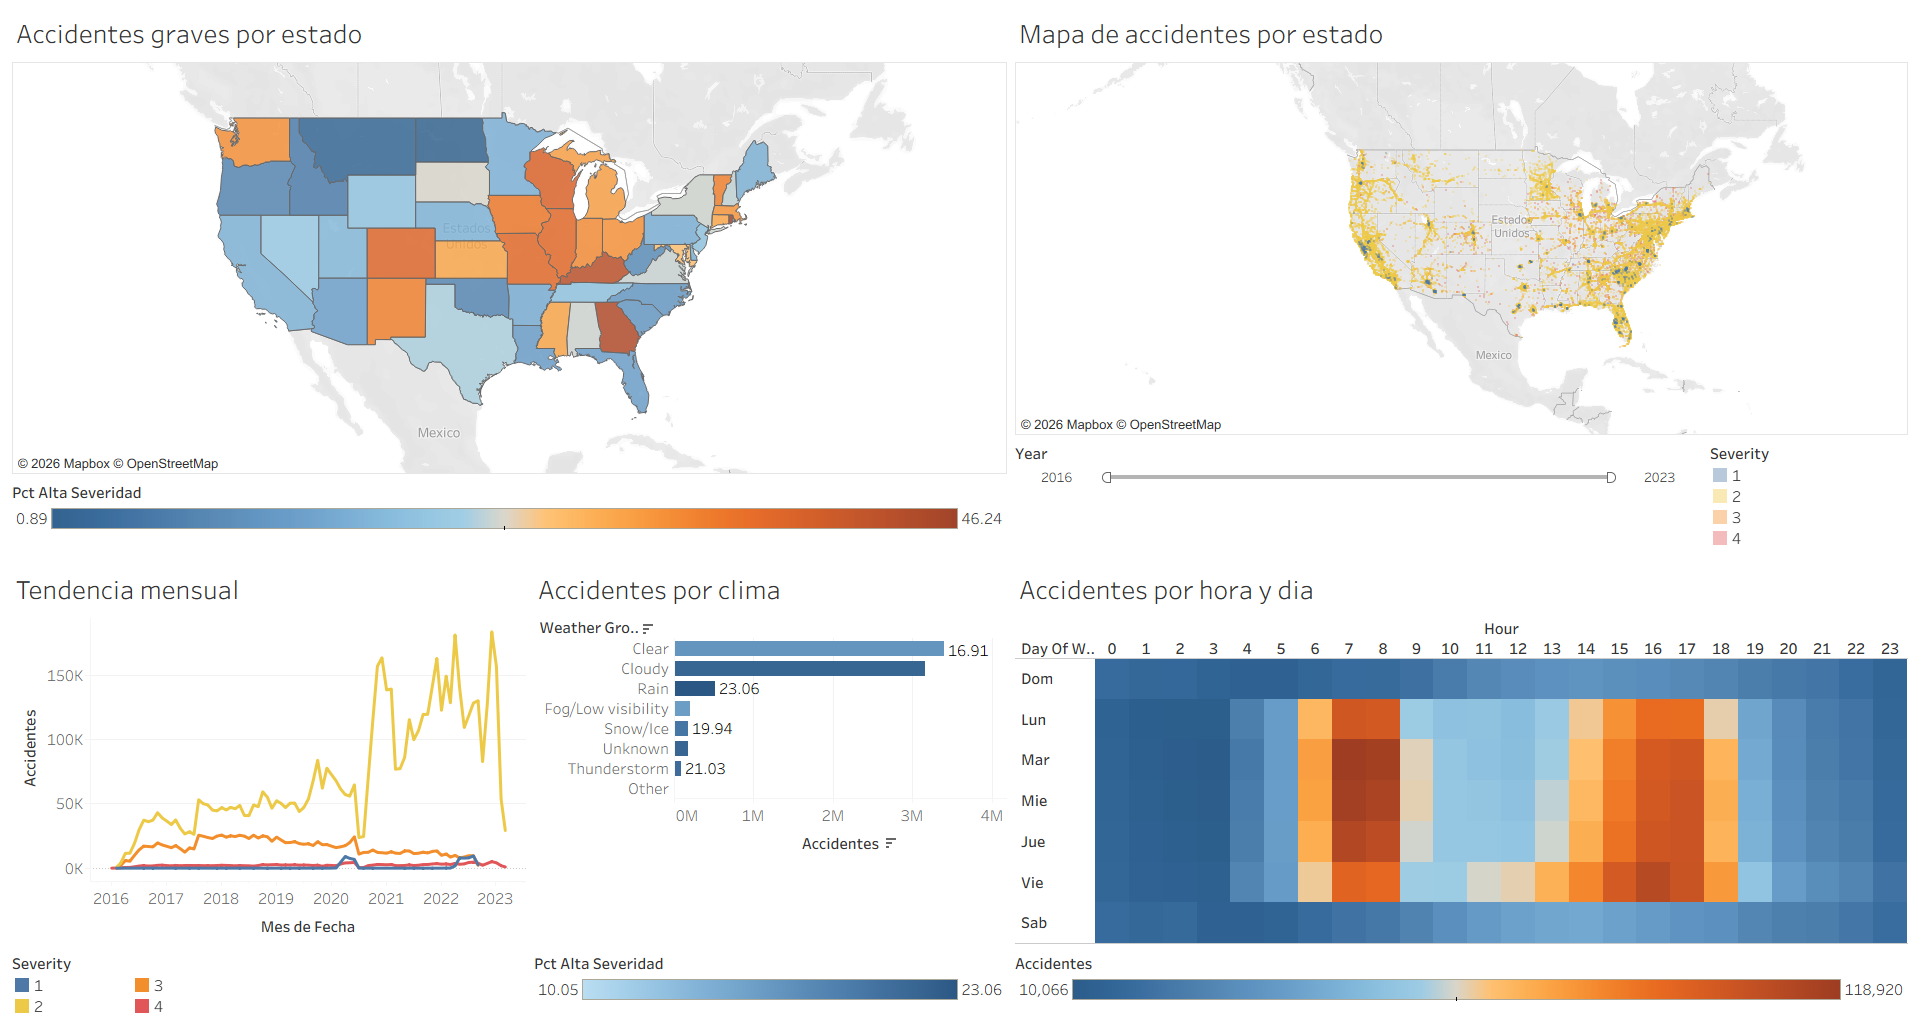


### 7.2 Interpretación del tablero

**1. Accidentes graves por estado.**
- El porcentaje de alta severidad va de 0.89 % a 46.24 % según el estado. Los valores más altos se concentran en Georgia
  y en el bloque del Medio Oeste y los Grandes Lagos (IL, WI, MI, IN, OH, KY, MO), además de CO, NM y WA.
- Los más bajos están en el noroeste y las Montañas (MT, ND, OR, ID) y en estados con mucho volumen, como CA, TX y FL.

**2. Mapa de accidentes por estado (mapa de puntos, muestra de 100 mil).**
- Los accidentes se concentran en California,
  Florida, Texas, la costa este y el sureste. Las Grandes Llanuras y las Montañas tienen pocos registros.
- El volumen refleja población, tráfico y cobertura de las fuentes de datos, no el riesgo por habitante. Un estado con más puntos no es necesariamente más peligroso.
- Predomina el color de severidad 2, coherente con que representa ~80 % de los registros.

**3. Tendencia mensual por severidad.**
- El número de registros de severidad 2 crece de forma escalonada: ~50 mil al mes en 2017–2019 y entre 100 y 180 mil en 2021–2022.
  Los saltos bruscos, como el de finales de 2020 a 2021, coinciden con cambios en la recolección de datos más que con un aumento real de accidentes.
- La severidad 3 se mantiene en ~20–25 mil al mes hasta 2020 y luego cae a niveles mucho más bajos, justo cuando la severidad 2 se dispara.
  Esto puede indicar que el criterio de etiquetado cambió y muchos accidentes que antes serían nivel 3 pasaron a nivel 2.
- La caída del último punto se debe a que los datos terminan en marzo de 2023 (mes incompleto), no a una reducción de accidentes.
- Las severidades 1 y 4 son marginales durante todo el periodo.

**4. Accidentes por clima.**
- La mayoría de los accidentes ocurre con cielo despejado (Clear) o nublado (Cloudy), simplemente porque son las condiciones más frecuentes.
  Las barras miden exposición, no riesgo.
- La proporción de alta severidad sí aumenta con mal clima: 23.06 % con lluvia, 21.03 % con tormenta y 19.94 % con nieve/hielo,
  frente a 16.91 % con cielo despejado.

**5. Accidentes por hora y día de la semana (heatmap).**
- De lunes a viernes hay dos picos que coinciden con las horas pico de tráfico:
  - **Mañana (7–8 h):** las celdas más oscuras de todo el mapa están de martes a jueves.
  - **Tarde (15–17 h):** el pico de la tarde dura más horas que el de la mañana, y el viernes alcanza su máximo a las 16 h.
- Entre ambos picos (9–13 h) el volumen baja a niveles intermedios. El viernes, ese valle del mediodía es menos profundo que el resto de la semana.
- En fin de semana (sábado y domingo) no hay picos, la actividad es baja y apenas sube un poco al mediodía y en la tarde.
  Las madrugadas (0–4 h) son las de menor volumen todos los días.
- El patrón sigue al volumen de tráfico de los traslados casa–trabajo: hay más accidentes cuando hay más vehículos en las vías.
- Las variables de hora y día casi no ayudan a predecir la severidad. La hora determina cuántos accidentes ocurren, no qué tan graves son.


## 8. Predicciones con datos nuevos
Se construyen accidentes hipotéticos con las mismas columnas de entrada y se pasan por el pipeline completo, que imputa, codifica y clasifica igual que en el entrenamiento. También se muestra una muestra de predicciones del conjunto de prueba.

In [ ]:
from pyspark.ml import PipelineModel
modelo = PipelineModel.load(RUTA_MODELO)

base = {c: 0 for c in POI}
nuevos = [
    dict(base, Escenario="Interestatal CA, madrugada, lluvia",       State="CA", Start_Lat=34.05, Start_Lng=-118.24, Temperature_F=55.0, Humidity_pct=90.0, Pressure_in=29.8, Visibility_mi=2.0,  Wind_Speed_mph=15.0, Month=1,  DayOfWeek=1, Hour=3,  Is_Weekend=1, Weather_Group="Rain",   Sunrise_Sunset="Night"),
    dict(base, Escenario="Cruce con semáforo FL, tarde despejada",   State="FL", Start_Lat=25.76, Start_Lng=-80.19,  Temperature_F=85.0, Humidity_pct=60.0, Pressure_in=30.0, Visibility_mi=10.0, Wind_Speed_mph=8.0,  Month=6,  DayOfWeek=4, Hour=17, Is_Weekend=0, Weather_Group="Clear",  Sunrise_Sunset="Day", Traffic_Signal=1, Crossing=1, Junction=1),
    dict(base, Escenario="Carretera rural GA, nieve",                State="GA", Start_Lat=33.75, Start_Lng=-84.39,  Temperature_F=28.0, Humidity_pct=85.0, Pressure_in=29.9, Visibility_mi=0.5,  Wind_Speed_mph=20.0, Month=1,  DayOfWeek=3, Hour=7,  Is_Weekend=0, Weather_Group="Snow/Ice", Sunrise_Sunset="Day"),
    dict(base, Escenario="Ciudad TX, hora pico, nublado",            State="TX", Start_Lat=29.76, Start_Lng=-95.37,  Temperature_F=75.0, Humidity_pct=70.0, Pressure_in=30.0, Visibility_mi=10.0, Wind_Speed_mph=10.0, Month=3,  DayOfWeek=2, Hour=8,  Is_Weekend=0, Weather_Group="Cloudy", Sunrise_Sunset="Day", Traffic_Signal=1),
    dict(base, Escenario="Datos incompletos (sin clima), NY noche",  State="NY", Start_Lat=40.71, Start_Lng=-74.01,  Temperature_F=None, Humidity_pct=None, Pressure_in=None, Visibility_mi=None, Wind_Speed_mph=None, Month=11, DayOfWeek=6, Hour=22, Is_Weekend=0, Weather_Group="Unknown", Sunrise_Sunset="Night"),
]

from pyspark.sql.types import StructType, StructField, StringType, DoubleType
esquema = StructType([StructField("Escenario", StringType())] +
                     [StructField(c, DoubleType() if c in NUM[:7] else IntegerType()) for c in NUM] +
                     [StructField(c, StringType()) for c in CAT])
filas = [tuple(r[f.name] if r[f.name] is None or f.dataType == StringType() else
               (float(r[f.name]) if f.dataType == DoubleType() else int(r[f.name])) for f in esquema) for r in nuevos]
df_nuevos = spark.createDataFrame(filas, esquema)

with medir("Predicción de escenarios nuevos"):
    pred_nuevos = modelo.transform(df_nuevos).select("Escenario", F.col("prediction").cast("int").alias("Alta_Severidad"),
               F.round(p1("probability"), 3).alias("Prob_Alta")).toPandas()
print(pred_nuevos.to_string(index=False))

[Predicción de escenarios nuevos] 5.2 s | 2 jobs | 2 etapas | 3 tareas
                              Escenario  Alta_Severidad  Prob_Alta
     Interestatal CA, madrugada, lluvia               1      0.553
 Cruce con semáforo FL, tarde despejada               0      0.357
              Carretera rural GA, nieve               1      0.762
          Ciudad TX, hora pico, nublado               0      0.416
Datos incompletos (sin clima), NY noche               1      0.599


- **Escenarios clasificados como alta severidad:** nieve con visibilidad de 0.5 mi y sin cruces ni semáforos en GA (0.76),
  y lluvia de madrugada en CA (0.55).
- **Escenarios clasificados como baja severidad:** los dos casos con semáforo/cruce, FL de tarde despejada (0.36) y TX en hora pico (0.42).
  Esto es coherente con la importancia de `Crossing` y `Traffic_Signal`.
- El modelo no sabe si una vía es "interestatal" o "rural", solo ve la ausencia de cruces y semáforos y las coordenadas. GA y CA corresponden a Atlanta y Los Ángeles.
- **El caso con datos faltantes (NY) se clasifica como grave (0.60).** El modelo predice aunque falten datos de clima,
  pero `Weather_Group = "Unknown"` es una categoría propia que el modelo aprendió de los registros sin clima. Esos registros pueden concentrarse
  en ciertas fuentes o periodos, así que esta predicción es la menos confiable de las cinco.
- **Los puntajes no son probabilidades reales.** Por los pesos por clase, el modelo marca como graves al 45 % de los accidentes cuando la proporción
  real es 19 %. Además, la etiqueta cambió con el tiempo. En 2023 solo el 2.9 % fue de alta severidad. Un valor de 0.76 significa
  "riesgo alto comparado con otros accidentes", no "76 % de probabilidad".

In [ ]:
print("Muestra de predicciones sobre el conjunto de prueba:")
(pred_rf.select("State", "Hour", "Weather_Group", "High_Severity",
                F.col("prediction").cast("int").alias("Prediccion"),
                F.round(p1("probability"), 3).alias("Prob_Alta"))
        .sample(fraction=0.0005, seed=7).limit(15).show())

Muestra de predicciones sobre el conjunto de prueba:
+-----+----+-------------+-------------+----------+---------+
|State|Hour|Weather_Group|High_Severity|Prediccion|Prob_Alta|
+-----+----+-------------+-------------+----------+---------+
|   FL|   6|       Cloudy|            0|         0|    0.357|
|   FL|   9|        Clear|            0|         0|    0.458|
|   FL|   7|       Cloudy|            0|         0|    0.263|
|   FL|  12|       Cloudy|            1|         1|    0.528|
|   TX|  21|        Clear|            0|         1|    0.576|
|   TX|  17|       Cloudy|            0|         0|    0.293|
|   TX|  16|       Cloudy|            0|         0|    0.427|
|   TX|  18|       Cloudy|            0|         1|    0.616|
|   TX|  10|       Cloudy|            0|         1|    0.531|
|   CA|  19|        Clear|            0|         1|    0.607|
|   CA|  13|       Cloudy|            0|         1|    0.626|
|   CA|  20|       Cloudy|            0|         1|    0.655|
|   GA|  14|     

En esta muestra, 8 de los 14 accidentes de baja severidad se marcaron como graves, lo que refleja la tasa de falsos positivos.
`sample(...).limit(15)` toma las primeras filas muestreadas de las primeras particiones, por eso aparecen pocos estados.

### Resultados finales
- El Random Forest es el modelo final: AUC-ROC = 0.743 y AUC-PR = 0.410, frente a 0.702 y 0.356 de la regresión logística. Su discriminación es moderada: separa mejor que el azar, pero con mucho traslape entre clases.
- Con umbral 0.5 detecta el 73 % de los accidentes de alta severidad. De los que marca como graves, el 32 % realmente lo es (F1 clase 1 = 0.443). Es más útil para descartar accidentes graves (acierta el 91 % de sus predicciones "no grave") que para confirmarlos.
- Las variables más importantes son `Crossing`, `Traffic_Signal`, `Wind_Speed_mph`, `Pressure_in` y `Start_Lng`. Por grupos, el modelo se apoya
  en los elementos de la vía y la ubicación. La hora, el día y la categoría de clima casi no aportan.
- La ventaja del Random Forest sobre la regresión logística (+0.04 de AUC-ROC, +8.5 puntos de recall) indica que existen relaciones no lineales
  o interacciones, probablemente entre ubicación y tipo de vía, que un modelo lineal no captura.

In [ ]:
spark.stop()

### Link a repo de Github

[Github](https://github.com/AIPorDefinir/ai-model-tutsipink/blob/main/src/bigdata/visualizacion/a01712408_emiliano_camacho.ipynb)